# Fase A — Análisis Exploratorio (EDA): Hurto de motocicletas y automotores en Colombia

**Fuente:** reporte *Hurto por Modalidades* de la Policía Nacional (enero 2010 – julio 2026), 656.635 registros.

**Pregunta de negocio:** ¿es posible predecir la cantidad de hurtos de **motocicletas** que se presentarán en un **municipio** durante el **siguiente mes**, utilizando el comportamiento histórico de los hurtos y las variables disponibles en el dataset?

**Objetivo de esta fase:** entender qué hay en los datos, qué tan confiables son y qué nos dicen, en lenguaje de negocio, sobre el hurto de vehículos y en especial sobre la variable que vamos a predecir.

**Organización**
1. Carga y diagnóstico (vacíos, filas repetidas, llave del municipio, tipos de variable) · 2. Preparación mínima · 3. Variables numéricas: tabla municipio-año y **variable objetivo (motos por municipio-mes)** · 4. Histogramas · 5. Boxplots · 6. Correlación (Pearson y Spearman) · 7. Gráficos adicionales: líneas, Pareto, barras, estacionalidad, burbujas · 8. Perfil de víctimas · 9. Hallazgos, limitaciones e implicaciones para las fases B y C.

Antes de cada gráfico hay una explicación de **qué vamos a ver** y después una celda **Insight:** con la conclusión.

## 1. Carga y diagnóstico de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter

# ---------- estilo común para TODOS los gráficos ----------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.alpha": 0.35, "legend.frameon": False,
})

# Paleta fija: el mismo color significa lo mismo en todo el notebook
C_MOTO, C_AUTO = "#C44E52", "#4C72B0"     # motos = rojo, automotores = azul
C_OSC, C_CLARO = "#2F3B4C", "#9FB1C9"     # barras destacadas / barras de apoyo
C_LINEA, C_GRIS = "#E08A1E", "#8A8F98"    # línea acumulada de Pareto / referencias

miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # 14000 -> 14.000

def num(x, dec=0):
    """Formato colombiano: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

# Busca el CSV en las carpetas habituales del repo (ajusta la lista si lo guardaste en otro sitio)
ruta = None
for carpeta in [".", "..", "../data", "../datos", "data", "datos"]:
    hallados = sorted(Path(carpeta).glob("Reporte_Hurto*.csv"))
    if hallados:
        ruta = hallados[0]
        break
if ruta is None:
    raise FileNotFoundError("No encontré el CSV 'Reporte_Hurto...'. Ponlo junto al notebook o ajusta la lista de carpetas.")

df = pd.read_csv(ruta)
print("Archivo:", ruta.name)
print(f"Filas: {num(df.shape[0])} | Columnas: {df.shape[1]}")
df.head()

Archivo: Reporte_Hurto_por_Modalidades_Policía_Nacional_20260916.csv
Filas: 656.635 | Columnas: 9


,DEPARTAMENTO,MUNICIPIO,CODIGO DANE,ARMAS MEDIOS,FECHA HECHO,GENERO,GRUPO ETARIO,TIPO DE HURTO,CANTIDAD
0,ATLÁNTICO,Barranquilla (CT),8001000,NO REPORTADO,05/03/2014,FEMENINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1
1,META,Villavicencio (CT),50001000,NO REPORTADO,14/02/2014,FEMENINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1
2,NORTE DE SANTANDER,Los Patios,54405000,NO REPORTADO,21/02/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO MOTOCICLETAS,1
3,ANTIOQUIA,Amagá,5030000,NO REPORTADO,03/01/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO MOTOCICLETAS,1
4,META,Villavicencio (CT),50001000,NO REPORTADO,22/02/2014,MASCULINO,ADULTOS,ARTÍCULO 239. HURTO AUTOMOTORES,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 656635 entries, 0 to 656634
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   DEPARTAMENTO   656635 non-null  str  
 1   MUNICIPIO      656635 non-null  str  
 2   CODIGO DANE    656635 non-null  int64
 3   ARMAS MEDIOS   656635 non-null  str  
 4   FECHA HECHO    656635 non-null  str  
 5   GENERO         655923 non-null  str  
 6   GRUPO ETARIO   656430 non-null  str  
 7   TIPO DE HURTO  656635 non-null  str  
 8   CANTIDAD       656635 non-null  int64
dtypes: int64(2), str(7)
memory usage: 103.6 MB


In [3]:
# ¿Cuántos datos faltan por columna?
faltantes = df.isna().sum().to_frame("vacíos")
faltantes["% del total"] = (faltantes["vacíos"] / len(df) * 100).round(3)
faltantes

,vacíos,% del total
DEPARTAMENTO,0,0.000
MUNICIPIO,0,0.000
CODIGO DANE,0,0.000
ARMAS MEDIOS,0,0.000
FECHA HECHO,0,0.000
GENERO,712,0.108
GRUPO ETARIO,205,0.031
TIPO DE HURTO,0,0.000
CANTIDAD,0,0.000


In [4]:
# ¿Hay filas idénticas? (Clase 5: diagnóstico de duplicados)
n_dup = df.duplicated().sum()
print(f"Filas idénticas: {num(n_dup)} ({n_dup / len(df):.1%} del archivo)")
print("Valores distintos de CANTIDAD:", df["CANTIDAD"].unique())

Filas idénticas: 218.780 (33.3% del archivo)
Valores distintos de CANTIDAD: [1]


In [5]:
# ¿El nombre del municipio basta para identificarlo?
pares = df.groupby(["DEPARTAMENTO", "MUNICIPIO"]).size().reset_index()
repetidos = pares["MUNICIPIO"].value_counts()
repetidos = repetidos[repetidos > 1]
print(f"Nombres de municipio distintos: {df['MUNICIPIO'].nunique()} | pares departamento-municipio: {len(pares)}")
print(f"Nombres que se repiten en más de un departamento: {len(repetidos)} (ej.: {', '.join(repetidos.index[:6])})")
print(f"Códigos DANE distintos: {num(df['CODIGO DANE'].nunique())} "
      f"(Aguachica aparece con {df.loc[df['MUNICIPIO'] == 'Aguachica', 'CODIGO DANE'].nunique()} códigos: los 3 últimos dígitos son el centro poblado)")

Nombres de municipio distintos: 976 | pares departamento-municipio: 1052
Nombres que se repiten en más de un departamento: 58 (ej.: La Unión, Villanueva, Buenavista, Argelia, Granada, Guadalupe)
Códigos DANE distintos: 2.200 (Aguachica aparece con 9 códigos: los 3 últimos dígitos son el centro poblado)


**Lectura rápida.** Cada fila es **un hecho de hurto** (un vehículo robado). Hay 9 columnas: 3 de lugar (`DEPARTAMENTO`, `MUNICIPIO`, `CODIGO DANE`), 1 de fecha, 4 que describen el hecho (`ARMAS MEDIOS`, `GENERO`, `GRUPO ETARIO`, `TIPO DE HURTO`) y 1 de conteo (`CANTIDAD`). Los datos vienen casi completos: solo faltan 712 valores en `GENERO` y 205 en `GRUPO ETARIO` (menos del 0,2 %).

**Filas idénticas: no se eliminan.** Una de cada tres filas está repetida, pero el archivo no trae un identificador del caso: dos hurtos distintos del mismo día, municipio, modalidad y perfil de víctima producen filas idénticas. Borrarlas **subestimaría** el problema (en Clase 5 se elimina un duplicado cuando es un error de captura; aquí es un hecho real).

**El nombre del municipio no es único.** Hay 58 nombres que existen en más de un departamento (Barbosa, Rionegro, La Unión…), así que agrupar solo por `MUNICIPIO` mezclaría lugares distintos. `CODIGO DANE` tampoco sirve directamente porque cambia según el centro poblado. Por eso, en todo el notebook **el municipio se identifica con el par departamento + municipio** (1.052 municipios).

**Tipos de variable (Clase 4: clasificar antes de analizar)**

| Variable | Tipo | Comentario |
|---|---|---|
| `DEPARTAMENTO`, `MUNICIPIO` | Nominal | Categorías sin orden |
| `CODIGO DANE` | Nominal (aunque es número) | Es una etiqueta del municipio; promediarlo no tiene sentido |
| `ARMAS MEDIOS`, `GENERO`, `TIPO DE HURTO` | Nominal | Modalidad, sexo de la víctima y vehículo robado |
| `GRUPO ETARIO` | Ordinal | Menores < Adolescentes < Adultos |
| `FECHA HECHO` | Temporal | Día del hecho (dd/mm/aaaa) |
| `CANTIDAD` | Discreta | Vale 1 en todas las filas (ver arriba): no aporta información |

## 2. Preparación mínima

In [6]:
# Fecha real (en el CSV viene como texto dd/mm/aaaa)
df["FECHA"] = pd.to_datetime(df["FECHA HECHO"], format="%d/%m/%Y")
df["ANIO"] = df["FECHA"].dt.year
df["MES"] = df["FECHA"].dt.month
df["DIA_SEM"] = df["FECHA"].dt.dayofweek          # 0 = lunes ... 6 = domingo

# Llave del municipio: el nombre se repite entre departamentos, así que usamos municipio + departamento
df["MUN_ID"] = df["MUNICIPIO"] + " · " + df["DEPARTAMENTO"]

def corto(mun_id):
    """Nombre corto para los gráficos: sin el departamento ni el sufijo (CT)."""
    return mun_id.split(" · ")[0].replace(" (CT)", "")

# Nombre corto del tipo de hurto
df["TIPO"] = df["TIPO DE HURTO"].str.replace("ARTÍCULO 239. HURTO ", "", regex=False).str.capitalize()

# Modalidad / medio: agrupamos las categorías casi iguales (hay 3 formas de decir "arma blanca")
mapa_armas = {
    "ARMA DE FUEGO": "Arma de fuego",
    "LLAVE MAESTRA": "Llave maestra",
    "SIN EMPLEO DE ARMAS": "Sin empleo de armas",
    "NO REPORTADO": "No reportado",
}
df["ARMAS"] = df["ARMAS MEDIOS"].map(mapa_armas).fillna("Otros (blancas, contundentes, escopolamina)")

# Género: unimos "sin dato" y "NO REPORTA"
df["GENERO"] = df["GENERO"].fillna("SIN DATO").replace("NO REPORTA", "SIN DATO")

# Grupo etario: variable ORDINAL -> categoría con orden
df["GRUPO ETARIO"] = pd.Categorical(df["GRUPO ETARIO"], categories=["MENORES", "ADOLESCENTES", "ADULTOS"], ordered=True)

def bonito(serie):
    """Nombres de departamento más legibles: BOGOTA -> Bogotá, NORTE DE SANTANDER -> Norte de Santander"""
    return (serie.str.title().str.replace(" De ", " de ", regex=False)
            .str.replace("Bogota", "Bogotá", regex=False))

print("Rango de fechas:", df["FECHA"].min().date(), "->", df["FECHA"].max().date())
print("Tipos de hurto:\n", df["TIPO"].value_counts().to_string())
print(f"Participación de motos: {(df['TIPO'] == 'Motocicletas').mean():.1%}")

Rango de fechas: 2010-01-01 -> 2026-07-31
Tipos de hurto:
 TIPO
Motocicletas    497736
Automotores     158899
Participación de motos: 75.8%


**Periodos que usamos.** 2026 solo llega hasta el 31 de julio y 2010 parece incompleto (lo vemos en la sección 7.1). Regla del notebook:
- **Comparaciones entre años** y tablas por año: solo años completos (2010–2025).
- **Variable objetivo** (motos por municipio-mes): enero 2011 – julio 2026.
- **Rankings y composiciones** (Pareto, modalidades, burbujas): todo el periodo, 2010 – jul 2026.

El periodo usado va indicado en el título de cada gráfico.

## 3. Variables numéricas: ¿cuáles hay y cuáles hay que construir?
En el archivo original solo hay dos columnas numéricas y **ninguna sirve para analizar** por sí sola:
- `CANTIDAD`: vale 1 en todas las filas (lo vimos en el diagnóstico), así que contar filas equivale a sumarla.
- `CODIGO DANE`: es un número, pero funciona como **etiqueta** del lugar.

Por eso construimos dos tablas con medidas numéricas reales:
1. **Tabla municipio-año**: describe el perfil del hurto en cada municipio (volumen, % motos, % arma de fuego, % mujeres).
2. **Tabla municipio-mes de motos**: es la **variable objetivo** de la pregunta de negocio.

### 3.1 Tabla municipio-año
Para cada municipio y cada año calculamos:
- `n_hurtos`: cuántos hurtos hubo (conteo).
- `dias_con_hurto`: en cuántos días distintos del año hubo al menos un hurto (de 1 a 366).
- `pct_moto`, `pct_arma_fuego`, `pct_mujer`: de cada 100 hurtos, cuántos fueron de motocicleta, con arma de fuego, o con víctima mujer.

Usamos solo 2010–2025 (años completos).

In [7]:
base = df[df["ANIO"] <= 2025].copy()
base["es_moto"] = base["TIPO"].eq("Motocicletas")
base["es_fuego"] = base["ARMAS"].eq("Arma de fuego")
base["es_mujer"] = base["GENERO"].eq("FEMENINO")

mun = (base.groupby(["MUN_ID", "ANIO"])
       .agg(n_hurtos=("TIPO", "size"),
            dias_con_hurto=("FECHA", "nunique"),
            pct_moto=("es_moto", "mean"),
            pct_arma_fuego=("es_fuego", "mean"),
            pct_mujer=("es_mujer", "mean"))
       .reset_index())
for c in ["pct_moto", "pct_arma_fuego", "pct_mujer"]:
    mun[c] = mun[c] * 100

num_cols = ["n_hurtos", "dias_con_hurto", "pct_moto", "pct_arma_fuego", "pct_mujer"]
nombres = {"n_hurtos": "Hurtos", "dias_con_hurto": "Días con hurto", "pct_moto": "% motos",
           "pct_arma_fuego": "% arma de fuego", "pct_mujer": "% víctima mujer"}

# Filtro de confiabilidad: los porcentajes solo son estables con suficientes casos
mun30 = mun[mun["n_hurtos"] >= 30]

print(f"Filas (municipio-año): {num(len(mun))}")
print(f"Municipio-años con 5 hurtos o menos: {(mun['n_hurtos'] <= 5).mean():.1%}")
print(f"Municipio-años con 30 hurtos o más: {num(len(mun30))} ({len(mun30) / len(mun):.1%})")
mun[num_cols].describe().round(1)

Filas (municipio-año): 11.861
Municipio-años con 5 hurtos o menos: 52.1%
Municipio-años con 30 hurtos o más: 1.932 (16.3%)


,n_hurtos,dias_con_hurto,pct_moto,pct_arma_fuego,pct_mujer
count,11861.0,11861.0,11861.0,11861.0,11861.0
mean,53.3,21.8,80.6,28.0,17.4
std,391.9,51.3,27.8,30.5,22.1
min,1.0,1.0,0.0,0.0,0.0
25%,2.0,2.0,71.4,0.0,0.0
50%,5.0,5.0,93.5,20.0,12.5
75%,16.0,15.0,100.0,50.0,25.0
max,9801.0,366.0,100.0,100.0,100.0


**Lectura rápida.** Con la llave correcta hay **11.861 municipio-años**. El municipio-año típico es pequeño: la **mediana es 5 hurtos**, pero el **promedio es 53** y el máximo es 9.801 (Bogotá, 2023). Cuando el promedio está tan lejos de la mediana, unos pocos casos enormes "arrastran" todo. Además, la mitad (52 %) tiene 5 hurtos o menos y solo el 16 % llega a 30, el umbral que usamos para que los porcentajes sean confiables.

### 3.2 Variable objetivo: hurtos de motos por municipio y mes
Para responder la pregunta de negocio necesitamos una fila por **municipio y mes** con el número de motos hurtadas. Dos decisiones importantes:
- **Los meses sin hurtos cuentan como 0.** El archivo solo trae hechos ocurridos: si un municipio no tuvo hurtos en un mes, ese mes no aparece. Para un modelo ese 0 es información, así que completamos la cuadrícula municipio × mes.
- **Periodo: enero 2011 – julio 2026.** 2010 parece subregistrado (sección 7.1) y julio de 2026 es el último mes completo.

Además calculamos la **historia** de cada municipio, que es lo que un modelo podría usar para predecir: motos hurtadas el mes anterior (`lag_1`), promedio de los 3 meses anteriores (`media_3m`), mismo mes del año anterior (`lag_12`) y automotores hurtados el mes anterior (`autos_lag_1`). Todas miran **solo hacia atrás**, para no usar información del futuro.

In [8]:
# Conteo mensual por municipio y tipo de vehículo (desde 2011)
desde = df[df["FECHA"] >= "2011-01-01"]
periodos = pd.period_range("2011-01", "2026-07", freq="M")
conteo_mes = (desde.groupby(["MUN_ID", desde["FECHA"].dt.to_period("M").rename("PERIODO"), "TIPO"]).size()
              .unstack(fill_value=0))

# Cuadrícula completa: municipios con al menos una moto hurtada x todos los meses (los meses sin hurtos = 0)
mun_moto = np.sort(desde.loc[desde["TIPO"] == "Motocicletas", "MUN_ID"].unique())
rejilla = pd.MultiIndex.from_product([mun_moto, periodos], names=["MUN_ID", "PERIODO"])
obj = (conteo_mes.reindex(rejilla, fill_value=0)
       .rename(columns={"Motocicletas": "motos", "Automotores": "autos"})
       .reset_index())

# Historia de cada municipio (solo meses anteriores)
g = obj.groupby("MUN_ID")["motos"]
obj["lag_1"] = g.shift(1)
obj["media_3m"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
obj["lag_12"] = g.shift(12)
obj["autos_lag_1"] = obj.groupby("MUN_ID")["autos"].shift(1)

print(f"Filas (municipio-mes): {num(len(obj))} = {num(len(mun_moto))} municipios x {len(periodos)} meses")
print(f"Municipio-meses con 0 motos hurtadas: {(obj['motos'] == 0).mean():.1%}")
print(f"Municipio-meses con 10 o más motos hurtadas: {(obj['motos'] >= 10).mean():.1%}")
obj[["motos", "lag_1", "media_3m", "lag_12", "autos_lag_1"]].describe().round(2)

Filas (municipio-mes): 194.854 = 1.042 municipios x 187 meses
Municipio-meses con 0 motos hurtadas: 71.1%
Municipio-meses con 10 o más motos hurtadas: 3.9%


TIPO,motos,lag_1,media_3m,lag_12,autos_lag_1
count,194854.00,193812.00,191728.00,182350.00,193812.00
mean,2.49,2.49,2.49,2.47,0.77
std,19.35,19.35,19.23,19.32,10.25
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00
75%,1.00,1.00,0.67,1.00,0.00
max,658.00,658.00,611.67,658.00,407.00


**Lectura rápida.** La variable objetivo tiene **194.854 filas** (1.042 municipios × 187 meses). **En el 71 % de los municipio-meses no se hurtó ninguna moto** y solo el 3,9 % llega a 10 o más. La media es 2,5 motos por municipio-mes, pero la mediana es 0 y el máximo 658 (Medellín, junio de 2023). Las variables de historia tienen la misma media que el objetivo (2,49), como debe ser: son la misma serie corrida en el tiempo.

## 4. Histogramas de las variables numéricas
**Qué vamos a ver:** un histograma agrupa los valores en "cajas" y muestra cuántos casos caen en cada una; sirve para ver la **forma** (dónde se concentran, si hay cola larga). Siguiendo la Clase 4, en cada panel marcamos la **media** (línea roja discontinua) y la **mediana** (línea naranja): si están lejos, la distribución es asimétrica y la mediana describe mejor el caso típico.

### 4.1 Tabla municipio-año
- Los dos primeros paneles muestran los hurtos en escala normal (recortada) y logarítmica.
- Los porcentajes se calculan solo con municipio-años de **30 hurtos o más**; con 1 o 2 casos el porcentaje salta a 0 % o 100 % y distorsiona la forma.

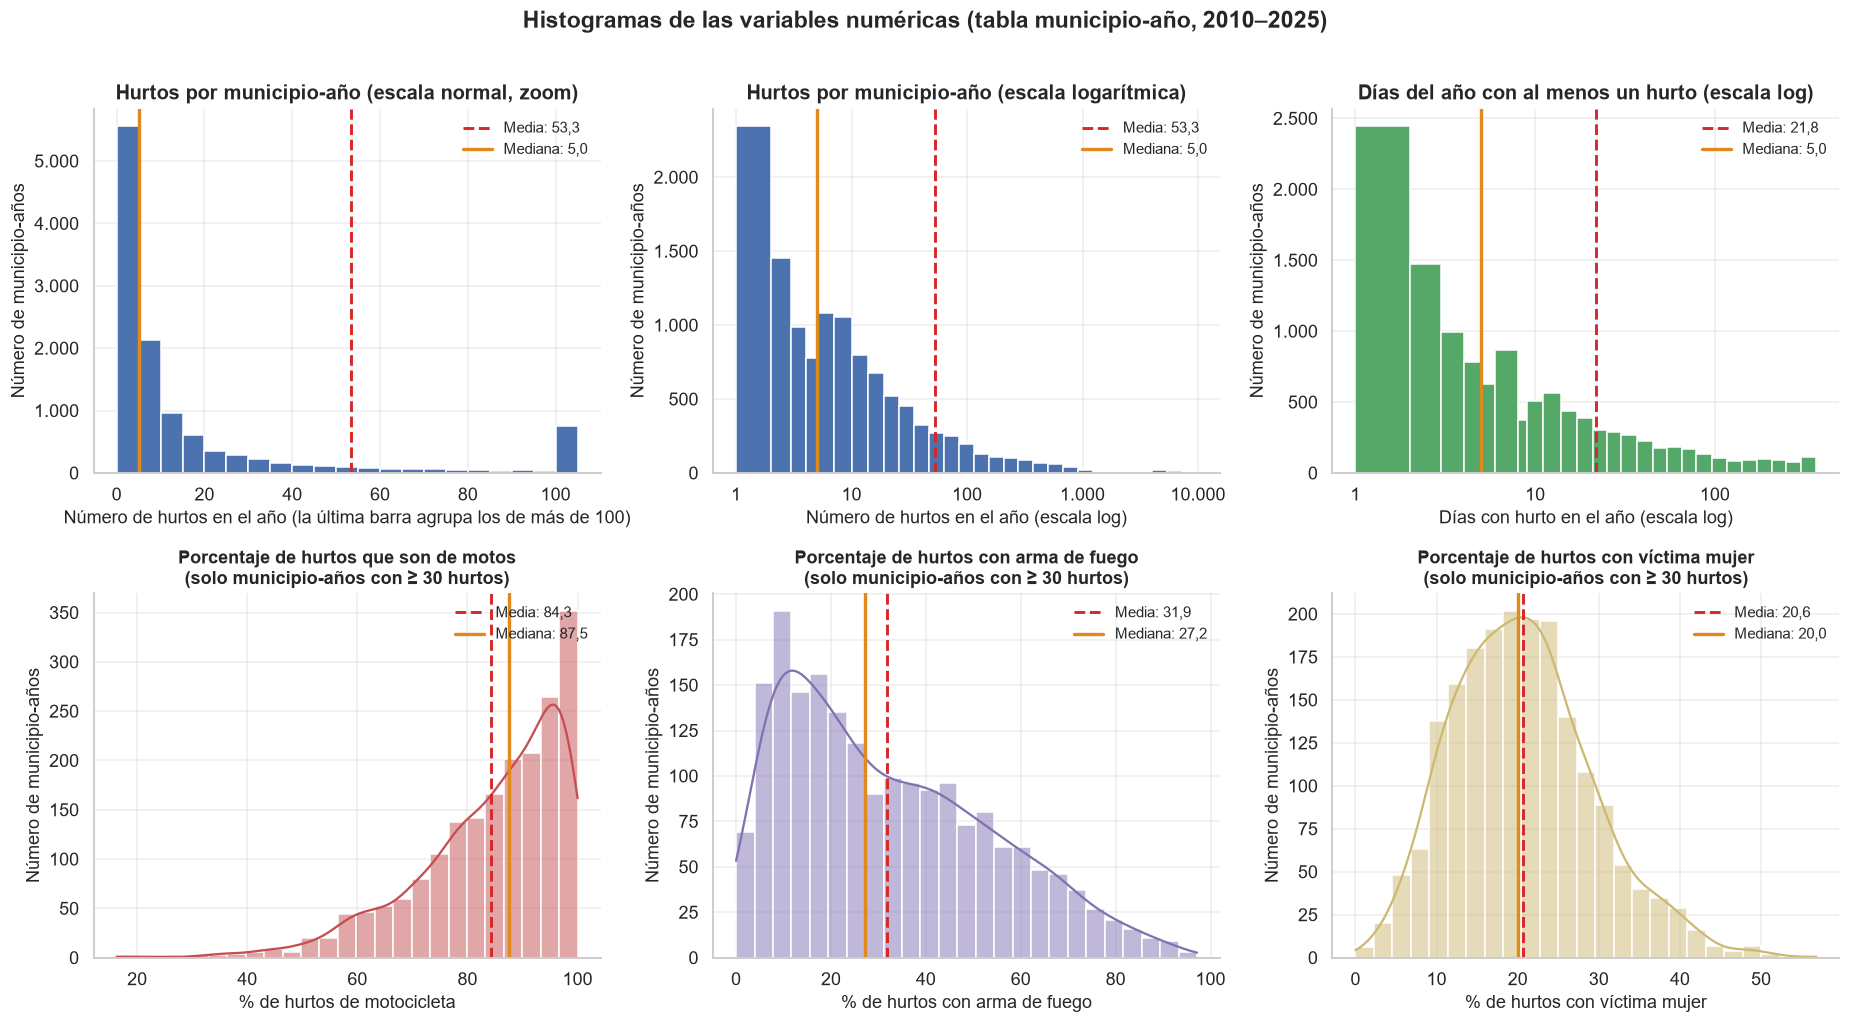

Municipio-años con más de 100 hurtos: 747 de 11.861
Medianas con ≥ 30 hurtos: {'% motos': 87.5, '% arma de fuego': 27.2, '% víctima mujer': 20.0}
Asimetría de los hurtos: 15.9 en escala normal -> 1.35 tras log(1 + x)


In [9]:
def bordes_log(serie, n=32):
    """Bordes enteros y crecientes para histogramas en escala log (evita cajas vacías con conteos pequeños)."""
    return np.unique(np.logspace(0, np.log10(serie.max() + 1), n).astype(int))

def marcar_centro(ax, serie):
    ax.axvline(serie.mean(), color="#D62728", ls="--", lw=1.9, label=f"Media: {num(serie.mean(), 1)}")
    ax.axvline(serie.median(), color=C_LINEA, ls="-", lw=2.2, label=f"Mediana: {num(serie.median(), 1)}")
    ax.legend(fontsize=9.5, loc="upper right")

fig, axes = plt.subplots(2, 3, figsize=(17, 9.2))

# (1) hurtos, escala normal recortada en 100
tope = 100
ax = axes[0, 0]
ax.hist(mun["n_hurtos"].clip(upper=tope + 5), bins=np.arange(0, tope + 10, 5), color=C_AUTO, edgecolor="white")
marcar_centro(ax, mun["n_hurtos"])
ax.set_title("Hurtos por municipio-año (escala normal, zoom)")
ax.set_xlabel(f"Número de hurtos en el año (la última barra agrupa los de más de {tope})")
ax.set_ylabel("Número de municipio-años")
ax.yaxis.set_major_formatter(miles)

# (2) hurtos, escala log
ax = axes[0, 1]
ax.hist(mun["n_hurtos"], bins=bordes_log(mun["n_hurtos"]), color=C_AUTO, edgecolor="white")
ax.set_xscale("log"); marcar_centro(ax, mun["n_hurtos"])
ax.set_title("Hurtos por municipio-año (escala logarítmica)")
ax.set_xlabel("Número de hurtos en el año (escala log)")
ax.set_ylabel("Número de municipio-años")
ax.xaxis.set_major_formatter(miles); ax.yaxis.set_major_formatter(miles)

# (3) días con hurto, escala log
ax = axes[0, 2]
ax.hist(mun["dias_con_hurto"], bins=bordes_log(mun["dias_con_hurto"]), color="#55A868", edgecolor="white")
ax.set_xscale("log"); marcar_centro(ax, mun["dias_con_hurto"])
ax.set_title("Días del año con al menos un hurto (escala log)")
ax.set_xlabel("Días con hurto en el año (escala log)")
ax.set_ylabel("Número de municipio-años")
ax.xaxis.set_major_formatter(miles); ax.yaxis.set_major_formatter(miles)

# (4-6) porcentajes (solo municipio-años con >= 30 hurtos) con KDE
for ax, col, color, titulo, xlab in [
    (axes[1, 0], "pct_moto", C_MOTO, "Porcentaje de hurtos que son de motos", "% de hurtos de motocicleta"),
    (axes[1, 1], "pct_arma_fuego", "#8172B2", "Porcentaje de hurtos con arma de fuego", "% de hurtos con arma de fuego"),
    (axes[1, 2], "pct_mujer", "#CCB974", "Porcentaje de hurtos con víctima mujer", "% de hurtos con víctima mujer")]:
    sns.histplot(mun30[col], bins=25, kde=True, color=color, edgecolor="white", ax=ax)
    marcar_centro(ax, mun30[col])
    ax.set_title(titulo + "\n(solo municipio-años con ≥ 30 hurtos)", fontsize=11.5)
    ax.set_xlabel(xlab)
    ax.set_ylabel("Número de municipio-años")

fig.suptitle("Histogramas de las variables numéricas (tabla municipio-año, 2010–2025)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
print(f"Municipio-años con más de {tope} hurtos: {num((mun['n_hurtos'] > tope).sum())} de {num(len(mun))}")
print("Medianas con ≥ 30 hurtos:", {nombres[c]: round(float(mun30[c].median()), 1) for c in ["pct_moto", "pct_arma_fuego", "pct_mujer"]})
print(f"Asimetría de los hurtos: {mun['n_hurtos'].skew():.1f} en escala normal -> {np.log1p(mun['n_hurtos']).skew():.2f} tras log(1 + x)")

**Insight:** el municipio-año típico es muy pequeño: la mitad registra 5 hurtos o menos, pero el promedio (53) lo arrastran unas pocas ciudades con miles de casos (747 de 11.861 superan los 100). En escala logarítmica la forma se vuelve casi simétrica (la asimetría baja de **15,9 a 1,35**), señal de que en la Fase B convendrá transformar los conteos con log(1 + x). Entre los municipios con volumen suficiente, el perfil típico es **88 % motos, 27 % arma de fuego y 20 % víctimas mujeres**.

### 4.2 Forma de la distribución: asimetría y curtosis (Clase 4)
- **Asimetría** > 1 → cola larga a la derecha (pocos casos enormes jalan el promedio). **Curtosis** alta → muchos más extremos que en una campana normal.
- **CV** (desviación estándar / media) compara la dispersión entre variables de distinta escala.

In [10]:
forma = pd.DataFrame({
    "Media": mun[num_cols].mean(),
    "Mediana": mun[num_cols].median(),
    "Desv. estándar": mun[num_cols].std(),
    "CV (%)": mun[num_cols].std() / mun[num_cols].mean() * 100,
    "Asimetría": mun[num_cols].skew(),
    "Curtosis (exceso)": mun[num_cols].kurt(),
}).rename(index=nombres).round(2)
forma

,Media,Mediana,Desv. estándar,CV (%),Asimetría,Curtosis (exceso)
Hurtos,53.29,5.00,391.85,735.37,15.88,282.29
Días con hurto,21.84,5.00,51.27,234.73,4.27,20.03
% motos,80.63,93.55,27.84,34.53,-1.69,2.07
% arma de fuego,27.97,20.00,30.53,109.17,0.97,-0.06
% víctima mujer,17.35,12.50,22.10,127.38,1.92,4.35


### 4.3 Histograma de la variable objetivo (motos por municipio-mes)
**Qué vamos a ver:** a la izquierda, qué porcentaje de los municipio-meses tiene 0, 1, 2… motos hurtadas (zoom hasta 20); a la derecha, solo los meses con al menos un hurto, en escala logarítmica, para ver la cola de las grandes ciudades.

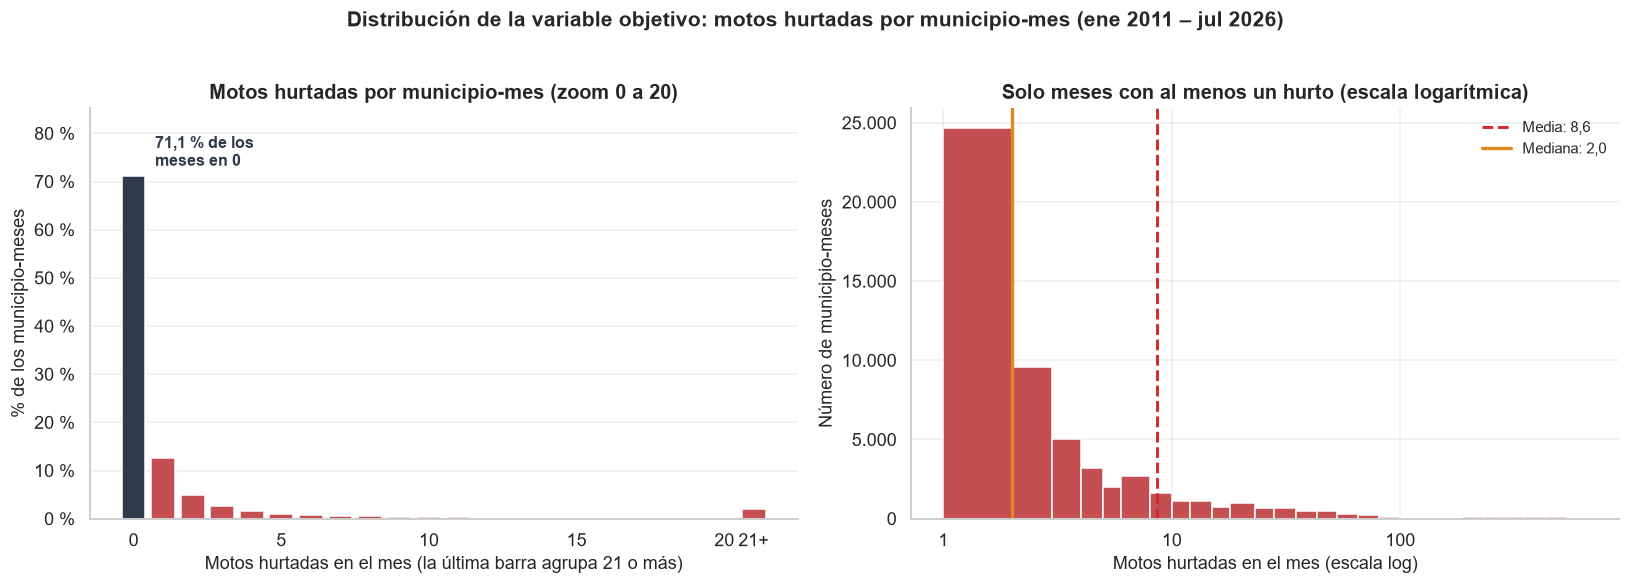

Media: 2.49 | mediana: 0 | máximo: 658 | asimetría: 18.6
Varianza / media = 150.7  (≈ 1 en una Poisson; mucho mayor = sobredispersión)
Municipios cuya mediana mensual es 0: 78.0%
Municipio-meses más altos:
                    MUN_ID PERIODO  motos
Medellín (CT) · ANTIOQUIA 2023-06    658
Medellín (CT) · ANTIOQUIA 2024-05    604
Medellín (CT) · ANTIOQUIA 2023-04    598


In [11]:
y = obj["motos"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# (1) frecuencia de 0, 1, 2, ... (los de 21 o más en la última barra)
ax = axes[0]
frec = y.clip(upper=21).value_counts(normalize=True).sort_index() * 100
barras = ax.bar(frec.index, frec.values, color=[C_OSC] + [C_MOTO] * (len(frec) - 1), width=0.8)
ax.annotate(f"{num(frec.iloc[0], 1)} % de los\nmeses en 0", (0, frec.iloc[0]), textcoords="offset points", xytext=(14, 4),
            ha="left", va="bottom", fontsize=10.5, fontweight="bold", color=C_OSC)
ax.set_xticks(list(range(0, 21, 5)) + [21], labels=[str(i) for i in range(0, 21, 5)] + ["21+"])
ax.set_ylim(0, frec.max() * 1.2)
ax.set_title("Motos hurtadas por municipio-mes (zoom 0 a 20)")
ax.set_xlabel("Motos hurtadas en el mes (la última barra agrupa 21 o más)")
ax.set_ylabel("% de los municipio-meses")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.grid(axis="x", visible=False)

# (2) solo meses con hurto, escala log
ax = axes[1]
positivos = y[y > 0]
ax.hist(positivos, bins=bordes_log(positivos), color=C_MOTO, edgecolor="white")
ax.set_xscale("log"); marcar_centro(ax, positivos)
ax.set_title("Solo meses con al menos un hurto (escala logarítmica)")
ax.set_xlabel("Motos hurtadas en el mes (escala log)")
ax.set_ylabel("Número de municipio-meses")
ax.xaxis.set_major_formatter(miles); ax.yaxis.set_major_formatter(miles)

fig.suptitle("Distribución de la variable objetivo: motos hurtadas por municipio-mes (ene 2011 – jul 2026)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Media: {y.mean():.2f} | mediana: {y.median():.0f} | máximo: {y.max()} | asimetría: {y.skew():.1f}")
print(f"Varianza / media = {y.var() / y.mean():.1f}  (≈ 1 en una Poisson; mucho mayor = sobredispersión)")
print(f"Municipios cuya mediana mensual es 0: {(obj.groupby('MUN_ID')['motos'].median() == 0).mean():.1%}")
print("Municipio-meses más altos:\n", obj.nlargest(3, "motos")[["MUN_ID", "PERIODO", "motos"]].to_string(index=False))

**Insight:** la variable que queremos predecir es casi siempre 0 o un número pequeño: **en el 71 % de los municipio-meses no hay ninguna moto hurtada** y en el 78 % de los municipios el mes típico es 0. Entre los meses con al menos un hurto, la mediana es 2 pero la media es 8,6, por la cola de Medellín, Bogotá y Cali (hasta 658 en un mes). La varianza es 150 veces la media: para la Fase C conviene modelar en escala log(1 + x) y revisar el error por separado en ciudades grandes y municipios pequeños, porque un mismo modelo no se equivoca igual en Bogotá que en un pueblo.

## 5. Boxplots para detectar valores atípicos (outliers)
### 5.1 Hurtos por municipio-año
**Qué vamos a ver:** un boxplot resume los datos: la **caja** cubre el 50 % central, la **línea** interior es la mediana y los **puntos** fuera de los bigotes son atípicos. Regla de Tukey (Clase 4 y 5): atípico = valor mayor que Q3 + 1,5 × IQR.

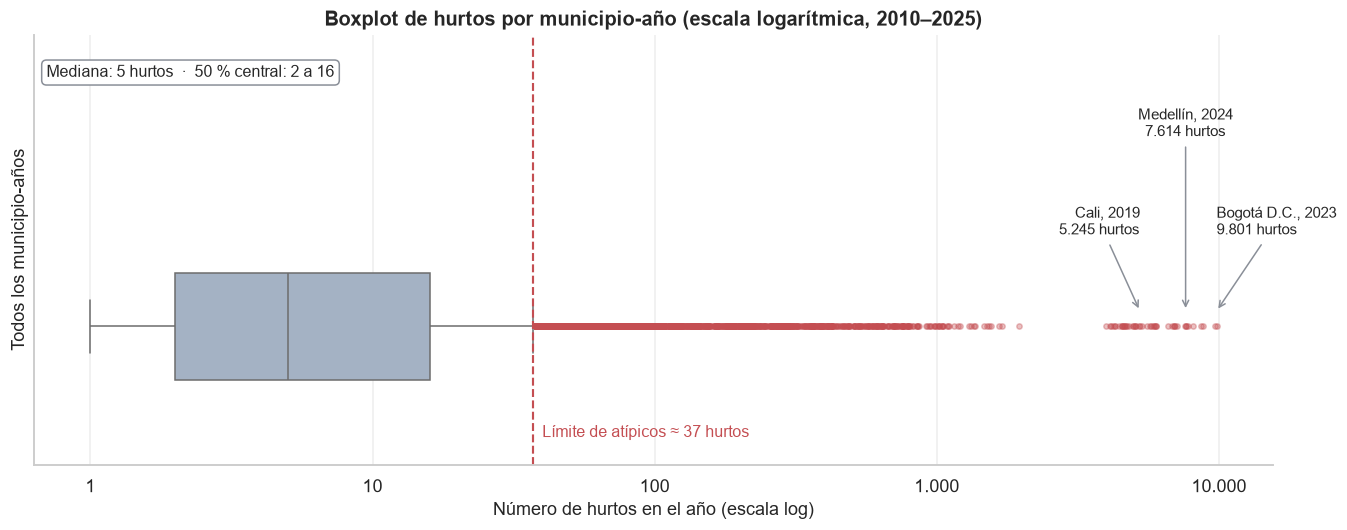

Límite de atípicos: 37 hurtos al año
Municipio-años atípicos: 1.610 de 11.861 (13.6%)
Municipios distintos que aparecen como atípicos: 179 de 1051

Los 10 municipios-año con más hurtos:


,MUN_ID,ANIO,n_hurtos
0,Bogotá D.C. (CT) · BOGOTA,2023,9801
1,Bogotá D.C. (CT) · BOGOTA,2024,9654
2,Bogotá D.C. (CT) · BOGOTA,2022,8780
3,Bogotá D.C. (CT) · BOGOTA,2021,8627
4,Bogotá D.C. (CT) · BOGOTA,2025,8116
5,Bogotá D.C. (CT) · BOGOTA,2019,7792
6,Bogotá D.C. (CT) · BOGOTA,2018,7647
7,Medellín (CT) · ANTIOQUIA,2024,7614
8,Medellín (CT) · ANTIOQUIA,2023,7547
9,Bogotá D.C. (CT) · BOGOTA,2020,7080


In [12]:
q1, q3 = mun["n_hurtos"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = mun[mun["n_hurtos"] > limite]
grandes = df["MUN_ID"].value_counts().head(3).index.tolist()   # las 3 ciudades con más hurtos

fig, ax = plt.subplots(figsize=(12.5, 5))
sns.boxplot(x=mun["n_hurtos"], color=C_CLARO, width=0.35, fliersize=3.5,
            flierprops={"markerfacecolor": C_MOTO, "markeredgecolor": C_MOTO, "alpha": 0.35}, ax=ax)
ax.set_xscale("log")
ax.axvline(limite, color=C_MOTO, ls="--", lw=1.4)
ax.text(limite * 1.08, -0.36, f"Límite de atípicos ≈ {limite:.0f} hurtos", color=C_MOTO, fontsize=10.5)

# etiquetas de las ciudades más grandes (su máximo anual)
posiciones = [(0.30, "right"), (0.62, "center"), (0.30, "left")]
extremos = sorted([(mun[mun["MUN_ID"] == c].nlargest(1, "n_hurtos").iloc[0], c) for c in grandes],
                  key=lambda t: t[0]["n_hurtos"])
for (fila, ciudad), (alto, ha) in zip(extremos, posiciones):
    ax.annotate(f"{corto(ciudad)}, {int(fila['ANIO'])}\n{num(fila['n_hurtos'])} hurtos",
                xy=(fila["n_hurtos"], 0.05), xytext=(fila["n_hurtos"], alto), ha=ha, fontsize=10,
                arrowprops={"arrowstyle": "->", "color": C_GRIS})

ax.text(0.01, 0.93, f"Mediana: {mun['n_hurtos'].median():.0f} hurtos  ·  50 % central: {q1:.0f} a {q3:.0f}",
        transform=ax.transAxes, fontsize=10.5, va="top", bbox={"boxstyle": "round", "fc": "white", "ec": C_GRIS})
ax.set_ylim(-0.45, 0.95)
ax.set_title("Boxplot de hurtos por municipio-año (escala logarítmica, 2010–2025)")
ax.set_xlabel("Número de hurtos en el año (escala log)")
ax.set_ylabel("Todos los municipio-años")
ax.set_yticks([])
ax.xaxis.set_major_formatter(miles)
plt.tight_layout()
plt.show()

print(f"Límite de atípicos: {limite:.0f} hurtos al año")
print(f"Municipio-años atípicos: {num(len(atipicos))} de {num(len(mun))} ({len(atipicos) / len(mun):.1%})")
print(f"Municipios distintos que aparecen como atípicos: {atipicos['MUN_ID'].nunique()} de {mun['MUN_ID'].nunique()}")
print("\nLos 10 municipios-año con más hurtos:")
atipicos.sort_values("n_hurtos", ascending=False).head(10)[["MUN_ID", "ANIO", "n_hurtos"]].reset_index(drop=True)

**Insight:** la mitad de los municipio-años tiene entre 2 y 16 hurtos, y todo lo que pase de unos 37 se marca como atípico: son **1.610 casos (13,6 %)**, que vienen de 179 municipios. Los atípicos **no son errores de captura**: son las ciudades grandes (Bogotá llega a 9.801 en 2023 y Medellín a 7.614 en 2024), donde el problema es de otra escala. Por eso no se eliminan; en la Fase B se tratarán con una transformación logarítmica en lugar de borrarlos.

### 5.2 Totales mensuales del país, por año
**Qué vamos a ver:** para cada año, cómo varían los 12 totales mensuales. La **línea roja** une las medianas (la tendencia) y los **puntos** sueltos son meses atípicos.

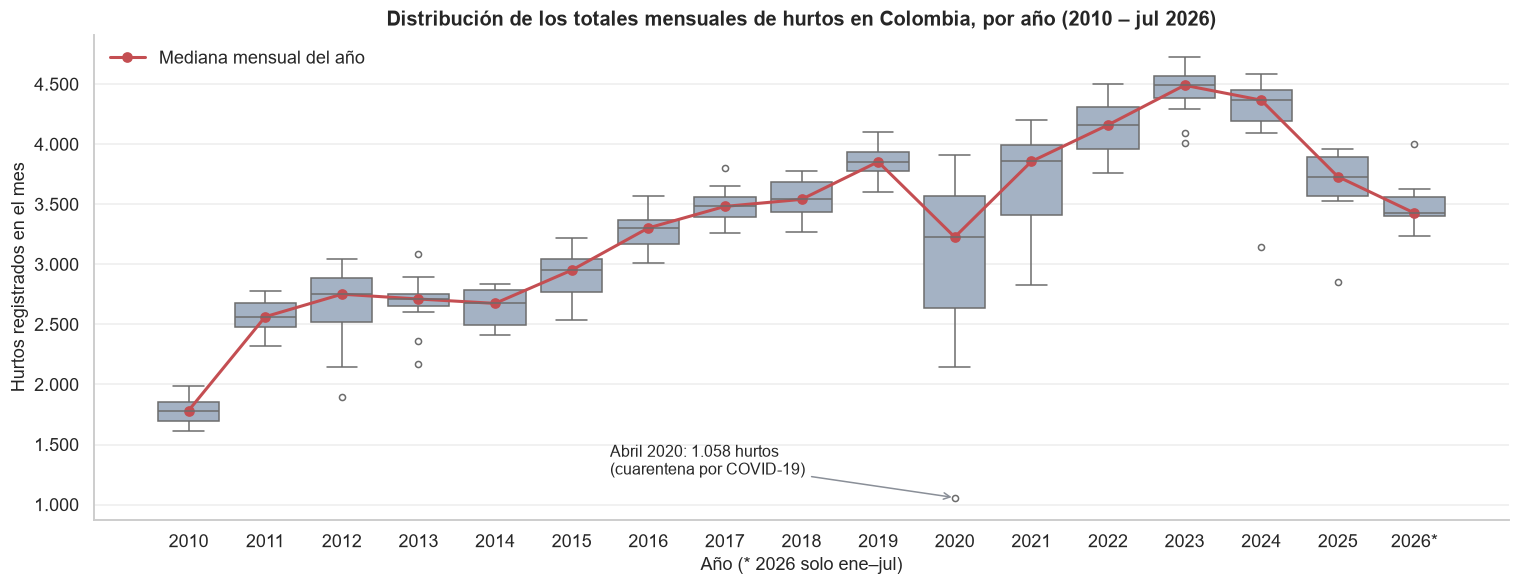

Mediana mensual por año:
 ANIO
2010    1783
2011    2564
2012    2751
2013    2711
2014    2675
2015    2951
2016    3303
2017    3482
2018    3541
2019    3854
2020    3227
2021    3856
2022    4160
2023    4491
2024    4367
2025    3730
2026    3427


In [13]:
mensual = df.groupby(["ANIO", "MES"]).size().rename("total").reset_index()
anios = sorted(mensual["ANIO"].unique())

fig, ax = plt.subplots(figsize=(14, 5.5))
sns.boxplot(data=mensual, x="ANIO", y="total", color=C_CLARO, fliersize=4, ax=ax)
medianas = mensual.groupby("ANIO")["total"].median()
ax.plot(range(len(anios)), medianas.values, color=C_MOTO, marker="o", lw=2, label="Mediana mensual del año")

peor = mensual.nsmallest(1, "total").iloc[0]
ax.annotate(f"Abril 2020: {num(peor['total'])} hurtos\n(cuarentena por COVID-19)",
            xy=(anios.index(int(peor["ANIO"])), peor["total"]), xytext=(anios.index(2020) - 4.5, 1250),
            arrowprops={"arrowstyle": "->", "color": C_GRIS}, fontsize=10.5)
ax.set_xticks(range(len(anios)))
ax.set_xticklabels([f"{a}*" if a == 2026 else str(a) for a in anios])
ax.set_title("Distribución de los totales mensuales de hurtos en Colombia, por año (2010 – jul 2026)")
ax.set_xlabel("Año (* 2026 solo ene–jul)")
ax.set_ylabel("Hurtos registrados en el mes")
ax.yaxis.set_major_formatter(miles)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print("Mediana mensual por año:\n", medianas.astype(int).to_string())

**Insight:** el mes típico pasó de **1.783 hurtos en 2010 a 4.491 en 2023**, y desde entonces baja (3.730 en 2025). El único mes realmente atípico es **abril de 2020 (1.058 hurtos)**, el confinamiento por COVID-19; 2020 también es el año con la caja más ancha por el desplome y la recuperación. Los saltos de 2010 a 2011 y la caída desde 2024 merecen validarse con la fuente.

### 5.3 Variable objetivo en los 10 municipios con más hurtos de motos
**Qué vamos a ver:** para cada uno de los 10 municipios con más motos hurtadas, cómo varían sus totales mensuales. Si las cajas de cada ciudad son estrechas y están en niveles muy distintos entre sí, el **nivel histórico del municipio** es la mejor pista para predecir su mes siguiente. Los puntos sueltos son meses atípicos según la regla de Tukey aplicada a cada ciudad.

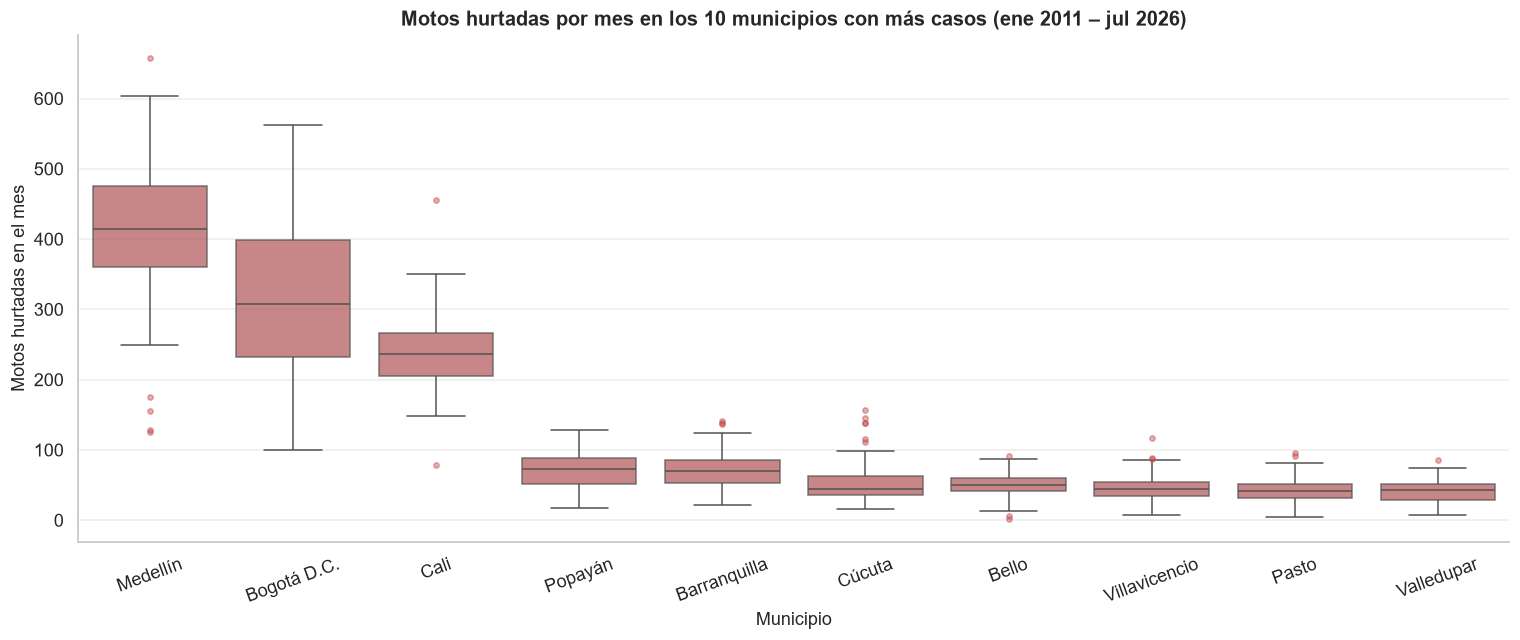

El promedio histórico de cada municipio explica el 92.5% de la variación de la variable objetivo
Los 10 municipios de la gráfica suman el 51.9% de las motos hurtadas


,media,Q1,mediana,Q3,maximo,meses_atipicos
Municipio,,,,,,
Medellín,419.0,361.0,415.0,476.0,658,5
Bogotá D.C.,314.0,232.0,307.0,399.0,563,0
Cali,238.0,206.0,236.0,266.0,455,2
Popayán,72.0,52.0,73.0,89.0,128,0
Barranquilla,71.0,53.0,70.0,85.0,141,3
Cúcuta,51.0,36.0,45.0,63.0,157,6
Bello,50.0,41.0,50.0,60.0,91,3
Villavicencio,46.0,34.0,44.0,55.0,117,3
Pasto,43.0,32.0,41.0,52.0,96,2


In [14]:
top10 = obj.groupby("MUN_ID")["motos"].sum().nlargest(10).index
caja = obj[obj["MUN_ID"].isin(top10)].assign(Municipio=lambda d: d["MUN_ID"].map(corto))
orden_top = [corto(m) for m in top10]

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=caja, x="Municipio", y="motos", order=orden_top, color=C_MOTO, fliersize=3.5,
            boxprops={"alpha": 0.75}, flierprops={"markerfacecolor": C_MOTO, "markeredgecolor": C_MOTO, "alpha": 0.45}, ax=ax)
ax.set_title("Motos hurtadas por mes en los 10 municipios con más casos (ene 2011 – jul 2026)")
ax.set_xlabel("Municipio")
ax.set_ylabel("Motos hurtadas en el mes")
ax.tick_params(axis="x", rotation=20)
ax.yaxis.set_major_formatter(miles)
plt.tight_layout()
plt.show()

def n_atipicos(s):
    """Meses fuera de los bigotes de Tukey (Q1 - 1,5 IQR, Q3 + 1,5 IQR)."""
    a, b = s.quantile([0.25, 0.75])
    return int(((s < a - 1.5 * (b - a)) | (s > b + 1.5 * (b - a))).sum())

resumen_top = caja.groupby("Municipio")["motos"].agg(media="mean", Q1=lambda s: s.quantile(0.25), mediana="median",
                                                      Q3=lambda s: s.quantile(0.75), maximo="max", meses_atipicos=n_atipicos).loc[orden_top]

# ¿Cuánto de la variación total se explica solo con "en qué municipio estamos"?
prom_mun = obj.groupby("MUN_ID")["motos"].transform("mean")
r2_mun = 1 - ((obj["motos"] - prom_mun) ** 2).sum() / ((obj["motos"] - obj["motos"].mean()) ** 2).sum()
print(f"El promedio histórico de cada municipio explica el {r2_mun:.1%} de la variación de la variable objetivo")
print(f"Los 10 municipios de la gráfica suman el {caja['motos'].sum() / obj['motos'].sum():.1%} de las motos hurtadas")
resumen_top.round(0)

**Insight:** cada ciudad se mueve en su propia franja: Medellín ronda **415 motos al mes**, Bogotá 307 y Cali 236, mientras Popayán y Barranquilla están cerca de 70; las cajas de las tres grandes casi no se cruzan con las demás. Solo con saber **en qué municipio estamos** (su promedio histórico) se explica el **92,5 % de la variación** de la variable objetivo, aunque esa cifra la dominan las diferencias entre ciudades grandes y pequeñas. Los meses atípicos son pocos (0 a 6 por ciudad) y tienen explicación: caídas de registro en noviembre–diciembre de 2012 (Medellín y Bello), la cuarentena de abril de 2020 (Cali: 79) y picos puntuales como Cúcuta en agosto–noviembre de 2015 o Cali en junio de 2021. No se eliminan, pero conviene marcarlos en la Fase B. Estos 10 municipios suman el 52 % de las motos hurtadas.

## 6. Heatmap de correlación (Pearson y Spearman)
**Qué vamos a ver:** la correlación mide si dos variables "suben y bajan juntas" (de −1 a 1; cerca de 0 = sin relación). **Pearson** busca relaciones en línea recta y se deja influir por los extremos; **Spearman** compara solo el orden y resiste mejor la cola larga que vimos (por eso la Clase 4 lo recomienda para datos con outliers).

### 6.1 Perfil del hurto (tabla municipio-año)
Usamos solo municipio-años con **30 hurtos o más**, para que los porcentajes sean estables, y dejamos fuera `dias_con_hurto`, que crece casi mecánicamente con el número de hurtos y no aportaría nada nuevo.

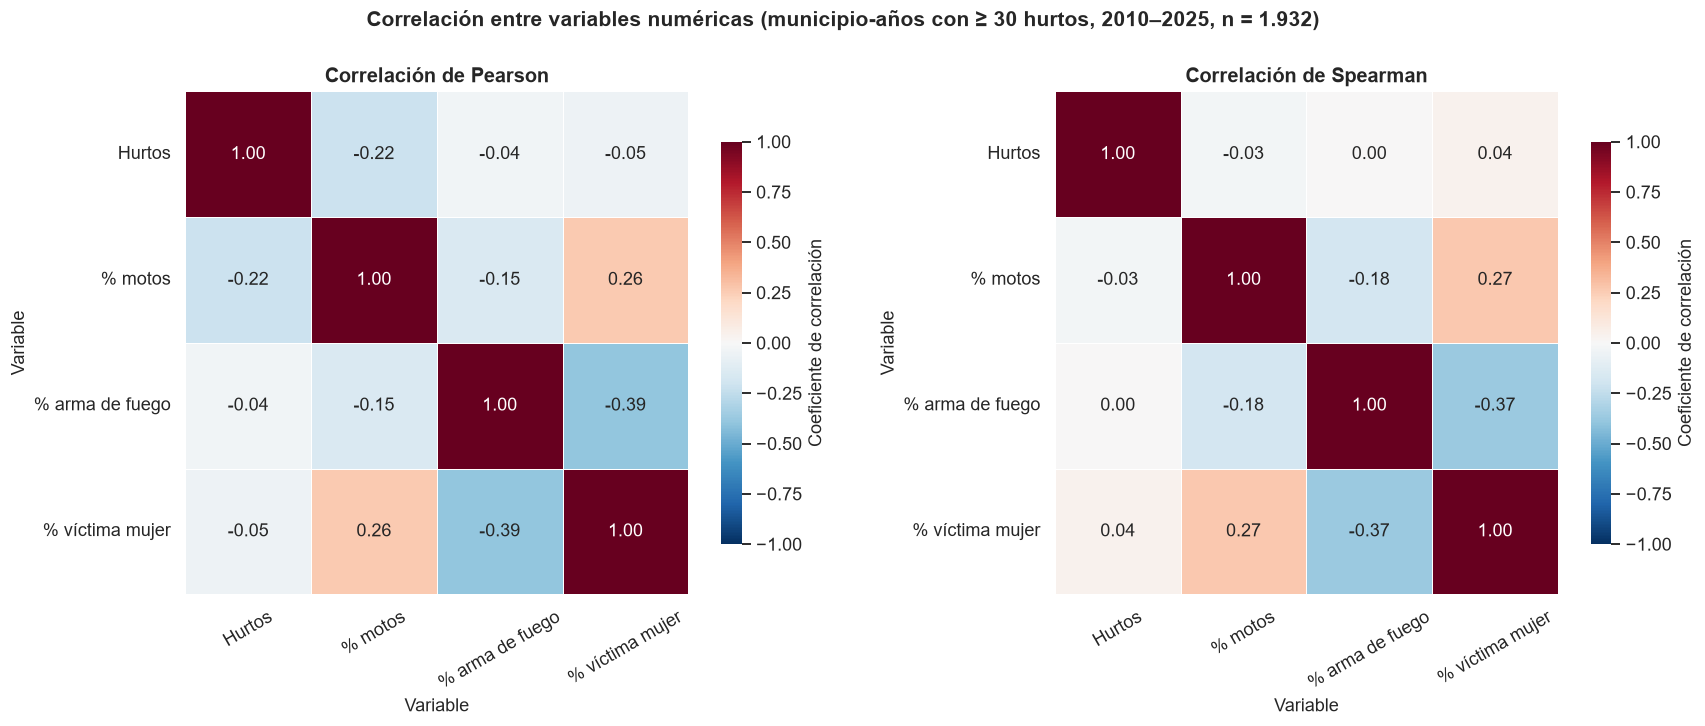

In [15]:
cols_corr = ["n_hurtos", "pct_moto", "pct_arma_fuego", "pct_mujer"]
datos_corr = mun30[cols_corr].rename(columns=nombres)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(datos_corr.corr(method=metodo), annot=True, fmt=".2f", annot_kws={"fontsize": 12},
                cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=0.6,
                cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlación"}, ax=ax)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
    ax.set_xlabel("Variable")
    ax.set_ylabel("Variable")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"Correlación entre variables numéricas (municipio-años con ≥ 30 hurtos, 2010–2025, n = {num(len(mun30))})", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** entre municipios con volumen suficiente, **el número de hurtos no se relaciona con el perfil del hurto** (Spearman entre −0,03 y 0,04): una ciudad grande no es, por sí sola, más violenta ni tiene más víctimas mujeres. Ojo: si se incluyen los municipios con muy pocos casos aparecen correlaciones engañosas, porque sus porcentajes saltan entre 0 % y 100 %. Lo que sí se ve es un patrón entre perfiles: donde pesa más el arma de fuego hay menos víctimas mujeres (−0,37) y donde pesan más las motos hay algo más de víctimas mujeres (0,27). Es correlación, no causalidad.

### 6.2 ¿La historia del municipio anticipa el mes siguiente? (variable objetivo)
**Qué vamos a ver:** la correlación entre las motos hurtadas en un mes y la historia del municipio: el mes anterior, el promedio de los 3 meses anteriores, el mismo mes del año anterior y los automotores hurtados el mes anterior. Es la primera prueba de que la pregunta de negocio tiene respuesta.

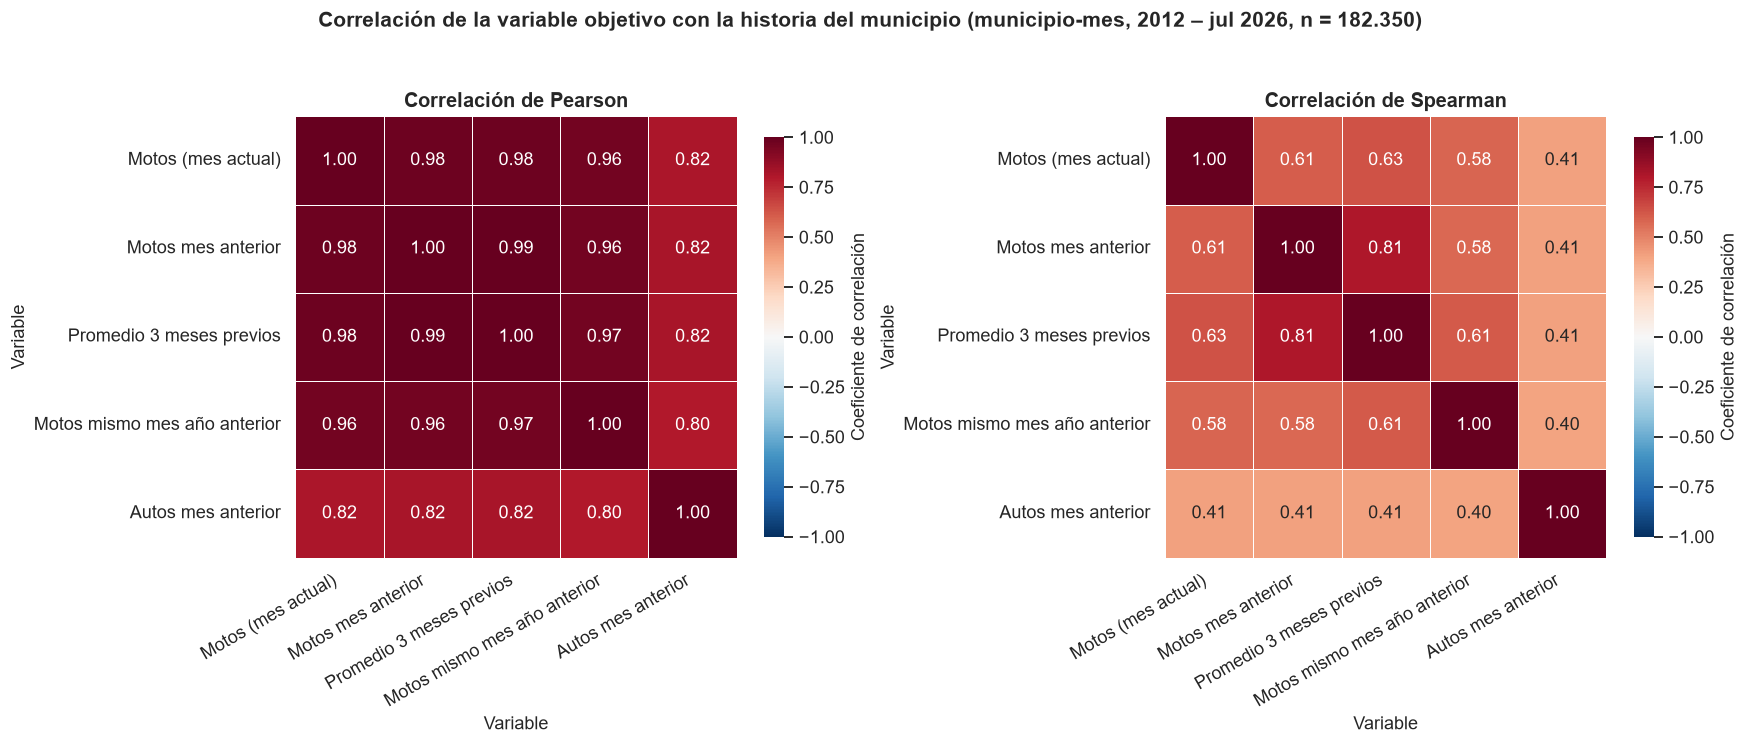

Municipios con menos de 5 motos/mes en promedio: 977 de 1042
  En ellos, Spearman motos vs mes anterior = 0.48 | vs promedio 3 meses = 0.53


In [16]:
hist_cols = {"motos": "Motos (mes actual)", "lag_1": "Motos mes anterior", "media_3m": "Promedio 3 meses previos",
             "lag_12": "Motos mismo mes año anterior", "autos_lag_1": "Autos mes anterior"}
datos_obj = obj.dropna(subset=list(hist_cols))[list(hist_cols)].rename(columns=hist_cols)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.6))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(datos_obj.corr(method=metodo), annot=True, fmt=".2f", annot_kws={"fontsize": 12},
                cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=0.6,
                cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlación"}, ax=ax)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
    ax.set_xlabel("Variable")
    ax.set_ylabel("Variable")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.suptitle(f"Correlación de la variable objetivo con la historia del municipio (municipio-mes, 2012 – jul 2026, n = {num(len(datos_obj))})",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Pearson lo dominan las grandes ciudades: revisamos también los municipios pequeños
pequenos = obj[obj.groupby("MUN_ID")["motos"].transform("mean") < 5].dropna(subset=["lag_1"])
print(f"Municipios con menos de 5 motos/mes en promedio: {pequenos['MUN_ID'].nunique()} de {obj['MUN_ID'].nunique()}")
print(f"  En ellos, Spearman motos vs mes anterior = {pequenos['motos'].corr(pequenos['lag_1'], method='spearman'):.2f}"
      f" | vs promedio 3 meses = {pequenos['motos'].corr(pequenos['media_3m'], method='spearman'):.2f}")

**Insight:** la historia reciente sí anticipa el mes siguiente. Con Pearson la relación es casi perfecta (0,98 con el mes anterior y con el promedio de 3 meses), pero esa cifra la inflan las grandes ciudades. Con **Spearman**, que resiste mejor la cola larga, sigue siendo moderada-alta: 0,61 con el mes anterior y **0,63 con el promedio de 3 meses**. En los 977 municipios pequeños (menos de 5 motos al mes) se mantiene en 0,48–0,53. Los automotores del mes anterior aportan menos (0,41) y el mismo mes del año anterior (0,58) no supera a la historia reciente, coherente con la poca estacionalidad (sección 7.5). Para la Fase C, el promedio de los últimos meses es la variable candidata más fuerte. Como las variables de historia están muy correlacionadas entre sí (0,81 a 0,99), en una regresión lineal habrá que vigilar la multicolinealidad.

### 6.3 Dispersión: mes anterior vs. mes actual
**Qué vamos a ver:** cada celda hexagonal agrupa municipio-meses según cuántas motos se hurtaron el mes anterior (eje X) y en el mes actual (eje Y); el color indica cuántos casos caen en ella. Ambos ejes están en escala logarítmica para que quepan desde los pueblos hasta Bogotá. Si los puntos se pegan a la diagonal, **"el mes siguiente se parece al anterior"**. Se omiten los pares en que ambos meses valen 0.

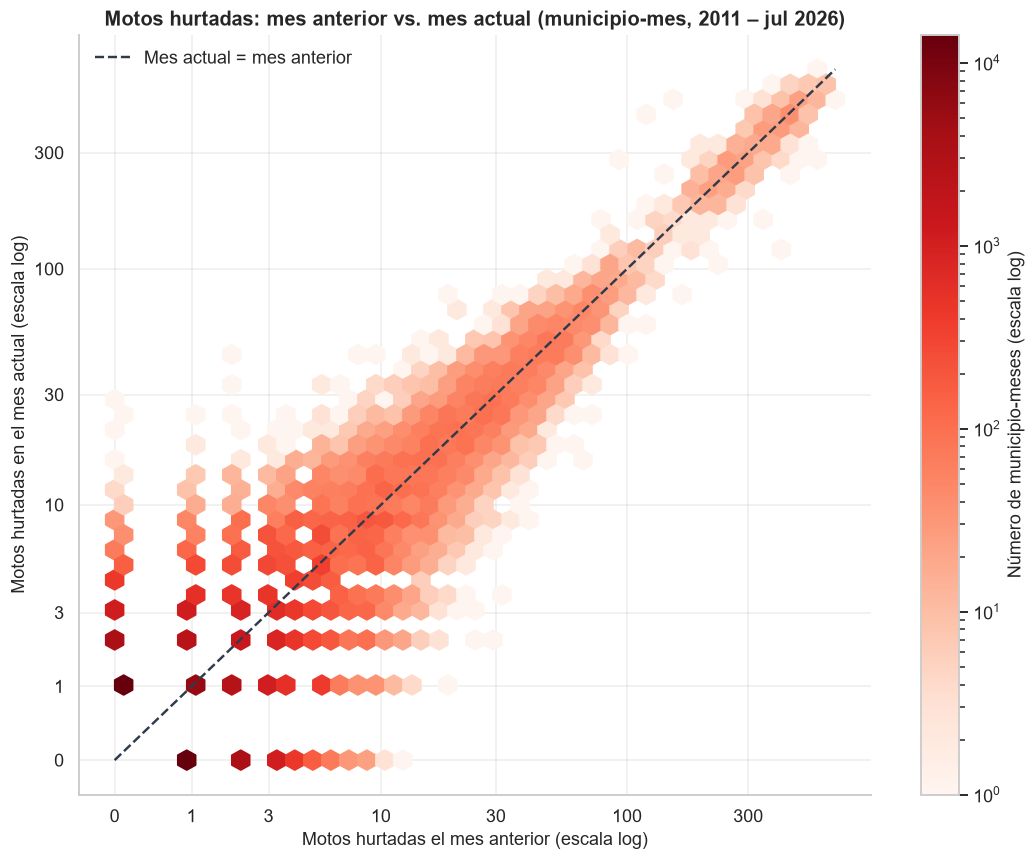

Predicción 'igual al mes anterior': error absoluto medio = 0.92 motos por municipio-mes
Predicción 'promedio de los 3 meses previos': error absoluto medio = 0.84 motos por municipio-mes
Pares omitidos por estar ambos meses en 0: 60.9%


In [17]:
pares_m = obj.dropna(subset=["lag_1"])
muestra = pares_m[(pares_m["motos"] > 0) | (pares_m["lag_1"] > 0)]
tope_ej = np.log1p(pares_m[["motos", "lag_1"]].max().max())
marcas = [m for m in [0, 1, 3, 10, 30, 100, 300, 1000] if np.log1p(m) <= tope_ej]

fig, ax = plt.subplots(figsize=(10, 8))
hb = ax.hexbin(np.log1p(muestra["lag_1"]), np.log1p(muestra["motos"]), gridsize=40, bins="log", cmap="Reds", mincnt=1)
ax.plot([0, tope_ej], [0, tope_ej], ls="--", color=C_OSC, lw=1.6, label="Mes actual = mes anterior")
ax.set_xticks(np.log1p(marcas), labels=[num(m) for m in marcas])
ax.set_yticks(np.log1p(marcas), labels=[num(m) for m in marcas])
fig.colorbar(hb, ax=ax, label="Número de municipio-meses (escala log)")
ax.set_title("Motos hurtadas: mes anterior vs. mes actual (municipio-mes, 2011 – jul 2026)")
ax.set_xlabel("Motos hurtadas el mes anterior (escala log)")
ax.set_ylabel("Motos hurtadas en el mes actual (escala log)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Línea base para la Fase C: ¿qué tan lejos queda una predicción ingenua?
base_c = obj.dropna(subset=["lag_1", "media_3m"])
for nombre, pred in [("igual al mes anterior", base_c["lag_1"]), ("promedio de los 3 meses previos", base_c["media_3m"])]:
    print(f"Predicción '{nombre}': error absoluto medio = {(base_c['motos'] - pred).abs().mean():.2f} motos por municipio-mes")
print(f"Pares omitidos por estar ambos meses en 0: {1 - len(muestra) / len(pares_m):.1%}")

**Insight:** los puntos se alinean con la diagonal: un municipio que tuvo muchos hurtos de motos el mes pasado casi siempre tiene muchos este mes. La nube se abre abajo a la izquierda porque, en los municipios pequeños, pasar de 1 a 3 hurtos es en buena parte azar. Esto fija una **línea base para la Fase C**: predecir "igual al mes anterior" se equivoca en promedio **0,92 motos por municipio-mes**, y "el promedio de los 3 meses previos" **0,84**. Un modelo de Machine Learning solo vale la pena si baja ese error.

## 7. Gráficos adicionales

### 7.1 Líneas — ¿cómo ha evolucionado el hurto en el tiempo?
**Qué vamos a ver:** el número de hurtos **por mes**, separado por tipo de vehículo. Las líneas finas son el dato mensual (con mucho "ruido") y las gruesas el **promedio móvil de 12 meses**, que deja ver la tendencia real.

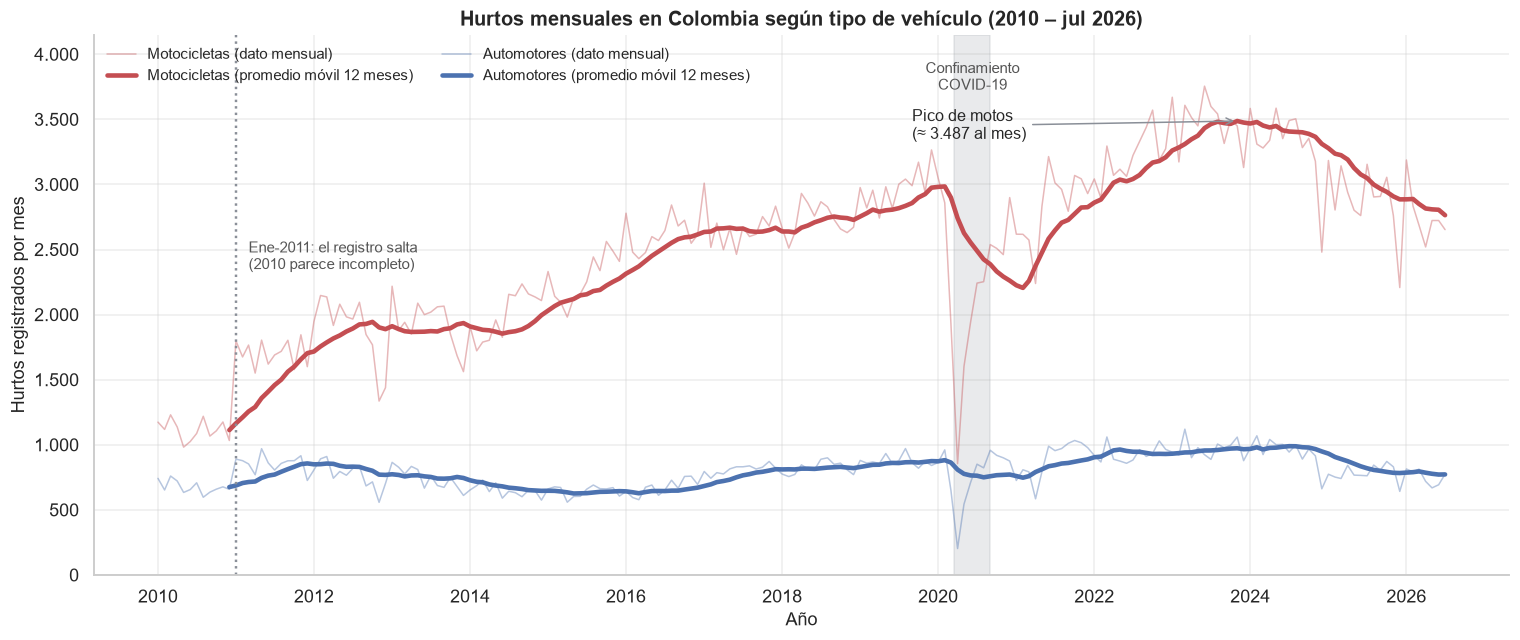

Hurtos por año:
 TIPO  Automotores  Motocicletas
ANIO                           
2010         8102         13354
2011        10282         20448
2012         9225         22661
2013         8941         23218
2014         7755         23947
2015         7727         27329
2016         8050         31390
2017         9750         32010
2018         9850         32733
2019        10496         35702
2020         9258         27137
2021        10658         33904
2022        11154         38504
2023        11592         41705
2024        11388         39741
2025         9397         34625
2026         5274         19328
Motocicletas: 2023 vs 2010 = x3.12 | 2023 vs 2011 = x2.04 | 2025 vs 2023 = -17.0% | 2020 vs 2019 = -24.0%
Automotores: 2023 vs 2010 = x1.43 | 2023 vs 2011 = x1.13 | 2025 vs 2023 = -18.9% | 2020 vs 2019 = -11.8%
Total nacional dic-2010: 1.691 -> ene-2011: 2.688 (+59%)
Medellín: dic-2010 151 -> ene-2011 546


In [18]:
mes = (df.groupby([df["FECHA"].dt.to_period("M").dt.to_timestamp().rename("PERIODO"), "TIPO"]).size().unstack())
mm12 = mes.rolling(12, min_periods=12).mean()

fig, ax = plt.subplots(figsize=(14, 6))
for tipo, color in [("Motocicletas", C_MOTO), ("Automotores", C_AUTO)]:
    ax.plot(mes.index, mes[tipo], color=color, lw=1, alpha=0.4, label=f"{tipo} (dato mensual)")
    ax.plot(mm12.index, mm12[tipo], color=color, lw=3, label=f"{tipo} (promedio móvil 12 meses)")

ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-09-01"), color=C_GRIS, alpha=0.18)
ax.text(pd.Timestamp("2020-06-10"), 3950, "Confinamiento\nCOVID-19", ha="center", va="top", fontsize=10, color="#555")
ax.axvline(pd.Timestamp("2011-01-01"), color=C_GRIS, ls=":", lw=1.6)
ax.text(pd.Timestamp("2011-03-01"), 2350, "Ene-2011: el registro salta\n(2010 parece incompleto)", fontsize=10, color="#555")

pico = mm12["Motocicletas"].idxmax()
ax.annotate(f"Pico de motos\n(≈ {num(mm12['Motocicletas'].max())} al mes)", xy=(pico, mm12["Motocicletas"].max()),
            xytext=(pd.Timestamp("2019-09-01"), 3350), arrowprops={"arrowstyle": "->", "color": C_GRIS}, fontsize=10.5)
ax.set_title("Hurtos mensuales en Colombia según tipo de vehículo (2010 – jul 2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Hurtos registrados por mes")
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(0, 4150)
ax.legend(loc="upper left", ncol=2, fontsize=9.5)
plt.tight_layout()
plt.show()

anual = df.groupby(["ANIO", "TIPO"]).size().unstack()
print("Hurtos por año:\n", anual.to_string())
for tipo in ["Motocicletas", "Automotores"]:
    print(f"{tipo}: 2023 vs 2010 = x{anual.loc[2023, tipo] / anual.loc[2010, tipo]:.2f} | 2023 vs 2011 = x{anual.loc[2023, tipo] / anual.loc[2011, tipo]:.2f} | 2025 vs 2023 = {anual.loc[2025, tipo] / anual.loc[2023, tipo] - 1:+.1%} | 2020 vs 2019 = {anual.loc[2020, tipo] / anual.loc[2019, tipo] - 1:+.1%}")
dic10, ene11 = mes.loc["2010-12-01"].sum(), mes.loc["2011-01-01"].sum()
med = df[df["MUN_ID"] == grandes[1]].groupby(df["FECHA"].dt.to_period("M")).size()
print(f"Total nacional dic-2010: {num(dic10)} -> ene-2011: {num(ene11)} ({ene11 / dic10 - 1:+.0%})")
print(f"{corto(grandes[1])}: dic-2010 {med.loc['2010-12']} -> ene-2011 {med.loc['2011-01']}")

**Insight:** las motos son el problema que crece: **≈ ×2,0 entre 2011 (20.448) y 2023 (41.705)**, mientras los automotores casi no cambian (×1,1). El ×3,1 que sale al comparar con 2010 está inflado: el registro nacional salta **+59 % de diciembre de 2010 a enero de 2011** (Medellín pasa de 151 a 546 casos al mes), señal de que 2010 está incompleto. Desde el pico de 2023 hay una baja sostenida (motos −17 % y automotores −19 % en 2025), y el confinamiento de 2020 recortó los hurtos en 24 % y 12 %.

### 7.2 Pareto — ¿dónde se concentra el problema? (Ley 80/20)
**La idea:** la Ley de Pareto dice que, en muchos fenómenos, **unas pocas causas explican la mayor parte del efecto** (la regla clásica: 20 % de las causas → 80 % del efecto).

**Qué vamos a ver:** ordenamos **todos** los municipios de mayor a menor número de hurtos y acumulamos su porcentaje del total nacional. Si el reparto fuera parejo, la curva sería la diagonal punteada; **mientras más se pegue la curva a la esquina superior izquierda, más concentrado está el problema**. El punto de cada curva marca qué porcentaje de los municipios hace falta para llegar al 80 % (línea gris). Separamos motos y automotores; el recuadro amplía el primer 10 % de los municipios.

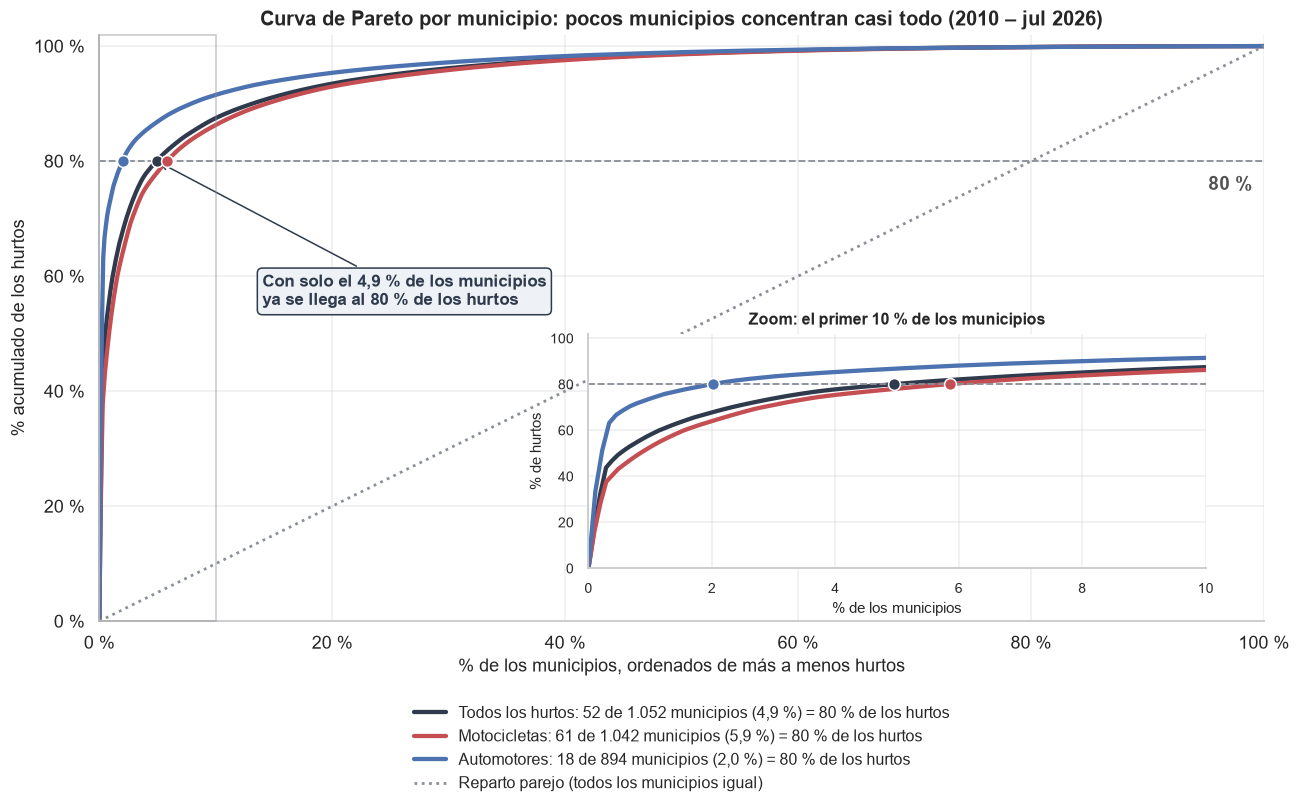

           Grupo  Municipios con hurto  Municipios para el 80 %  % de municipios  % que suman las 3 primeras ciudades
Todos los hurtos                  1052                       52              4.9                                 43.8
    Motocicletas                  1042                       61              5.9                                 37.6
     Automotores                   894                       18              2.0                                 63.2

Municipios para cubrir el 50 % de los hurtos: 6 | los 10 primeros suman: 57.4%
Las 3 primeras: Bogotá D.C., Medellín, Cali


In [19]:
series = [("Todos los hurtos", df, C_OSC), ("Motocicletas", df[df["TIPO"] == "Motocicletas"], C_MOTO),
          ("Automotores", df[df["TIPO"] == "Automotores"], C_AUTO)]

fig, ax = plt.subplots(figsize=(12, 7.6))
axin = ax.inset_axes([0.42, 0.09, 0.53, 0.40])
axin.set_facecolor("white"); axin.set_zorder(10)
resumen_pareto = []
for nombre, datos, color in series:
    c = datos["MUN_ID"].value_counts()
    x = np.r_[0, np.arange(1, len(c) + 1) / len(c) * 100]
    y_ac = np.r_[0, c.cumsum().values / c.sum() * 100]
    n80_t = int((c.cumsum() / c.sum() < 0.8).sum() + 1)
    resumen_pareto.append((nombre, len(c), n80_t, n80_t / len(c) * 100, c.head(3).sum() / c.sum() * 100))
    etiqueta = f"{nombre}: {n80_t} de {num(len(c))} municipios ({num(n80_t / len(c) * 100, 1)} %) = 80 % de los hurtos"
    for a in (ax, axin):
        a.plot(x, y_ac, color=color, lw=2.8, label=etiqueta if a is ax else None)
        a.scatter([n80_t / len(c) * 100], [80], color=color, s=60, zorder=6, edgecolor="white")
ax.plot([0, 100], [0, 100], ls=":", color=C_GRIS, lw=1.8, label="Reparto parejo (todos los municipios igual)")
for a in (ax, axin):
    a.axhline(80, color=C_GRIS, ls="--", lw=1.2)
ax.text(99, 75, "80 %", ha="right", color="#555", fontweight="bold")
pct80 = resumen_pareto[0][3]
ax.annotate(f"Con solo el {num(pct80, 1)} % de los municipios\nya se llega al 80 % de los hurtos", xy=(pct80, 80), xytext=(14, 55),
            fontsize=11, fontweight="bold", color=C_OSC, arrowprops={"arrowstyle": "->", "color": C_OSC},
            bbox={"boxstyle": "round", "fc": "#EEF2F7", "ec": C_OSC})
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
axin.set_xlim(0, 10); axin.set_ylim(0, 102)
axin.set_title("Zoom: el primer 10 % de los municipios", fontsize=10.5)
axin.set_xlabel("% de los municipios", fontsize=9.5); axin.set_ylabel("% de hurtos", fontsize=9.5)
axin.tick_params(labelsize=9)
ax.indicate_inset_zoom(axin, edgecolor=C_GRIS)
ax.set_title("Curva de Pareto por municipio: pocos municipios concentran casi todo (2010 – jul 2026)")
ax.set_xlabel("% de los municipios, ordenados de más a menos hurtos")
ax.set_ylabel("% acumulado de los hurtos")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, fontsize=10.5)
plt.tight_layout()
plt.show()

print(pd.DataFrame(resumen_pareto, columns=["Grupo", "Municipios con hurto", "Municipios para el 80 %", "% de municipios",
                                            "% que suman las 3 primeras ciudades"]).round(1).to_string(index=False))
conteo = df["MUN_ID"].value_counts()
c_acum = conteo.cumsum() / conteo.sum()
print(f"\nMunicipios para cubrir el 50 % de los hurtos: {int((c_acum < 0.5).sum() + 1)} | los 10 primeros suman: {c_acum.iloc[9]:.1%}")
print("Las 3 primeras:", ", ".join(corto(m) for m in conteo.index[:3]))

**Insight:** el problema es **más concentrado que la regla 80/20**: con solo **52 de 1.052 municipios (4,9 %)** se reúne el 80 % de los hurtos, 6 municipios llegan al 50 % y **Bogotá, Medellín y Cali suman el 44 %**. En **automotores** la concentración es extrema (18 municipios, el 2,0 %, hacen el 80 %, y las 3 ciudades grandes suman 63 %); en **motos** está algo más repartida (61 municipios, 5,9 %; 3 ciudades = 38 %). Contra el hurto de carros sirve una estrategia focalizada en pocas ciudades; contra el de motos hace falta cobertura en más territorios. Para el modelo, unas pocas ciudades pesarán muchísimo en el error si no se trabaja en escala logarítmica.

### 7.3 Barras — ¿cómo se comete el hurto de motos frente al de automotores?
**Qué vamos a ver:** para cada tipo de vehículo, el porcentaje de sus hurtos según la modalidad. Se compara en porcentaje (y no en cantidad) porque hay muchas más motos que automotores.

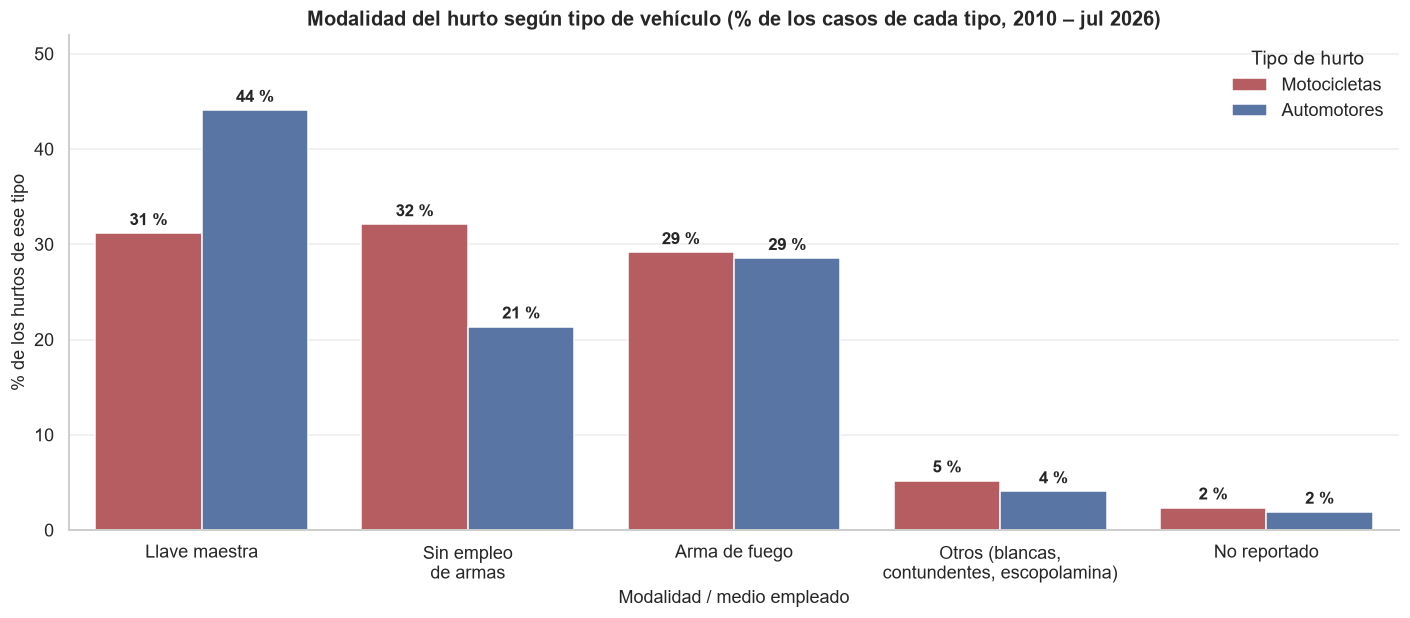

TIPO                                         Automotores  Motocicletas
ARMAS                                                                 
Llave maestra                                       44.1          31.2
Sin empleo de armas                                 21.4          32.1
Arma de fuego                                       28.6          29.2
Otros (blancas, contundentes, escopolamina)          4.1           5.2
No reportado                                         1.9           2.4


In [20]:
orden_a = ["Llave maestra", "Sin empleo de armas", "Arma de fuego", "Otros (blancas, contundentes, escopolamina)", "No reportado"]
pct = (pd.crosstab(df["ARMAS"], df["TIPO"], normalize="columns") * 100).loc[orden_a]
largo = pct.reset_index().melt(id_vars="ARMAS", var_name="Tipo de hurto", value_name="Porcentaje")

fig, ax = plt.subplots(figsize=(13, 5.8))
sns.barplot(data=largo, x="ARMAS", y="Porcentaje", hue="Tipo de hurto", hue_order=["Motocicletas", "Automotores"],
            palette={"Motocicletas": C_MOTO, "Automotores": C_AUTO}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f %%", padding=3, fontsize=11, fontweight="bold")
ax.set_title("Modalidad del hurto según tipo de vehículo (% de los casos de cada tipo, 2010 – jul 2026)")
ax.set_xlabel("Modalidad / medio empleado")
ax.set_ylabel("% de los hurtos de ese tipo")
ax.set_ylim(0, 52)
ax.set_xticks(range(len(orden_a)), labels=["Llave maestra", "Sin empleo\nde armas", "Arma de fuego", "Otros (blancas,\ncontundentes, escopolamina)", "No reportado"])
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(pct.round(1).to_string())

**Insight:** en **automotores domina la llave maestra (44 %)**, un hurto sin violencia; en motos pesa más el hurto "sin empleo de armas" (32 % frente a 21 %). El uso de arma de fuego es casi igual en ambos (≈ 29 %): cerca de 3 de cada 10 hurtos, sea moto o carro, implican una amenaza armada. Cada vehículo pide una estrategia distinta: tecnología antirrobo para carros, vigilancia y espacios seguros para motos.

### 7.4 Barras apiladas — ¿cambia la forma de hurtar con los años?
**Qué vamos a ver:** para cada año, cómo se reparte el 100 % de los hurtos entre las modalidades.

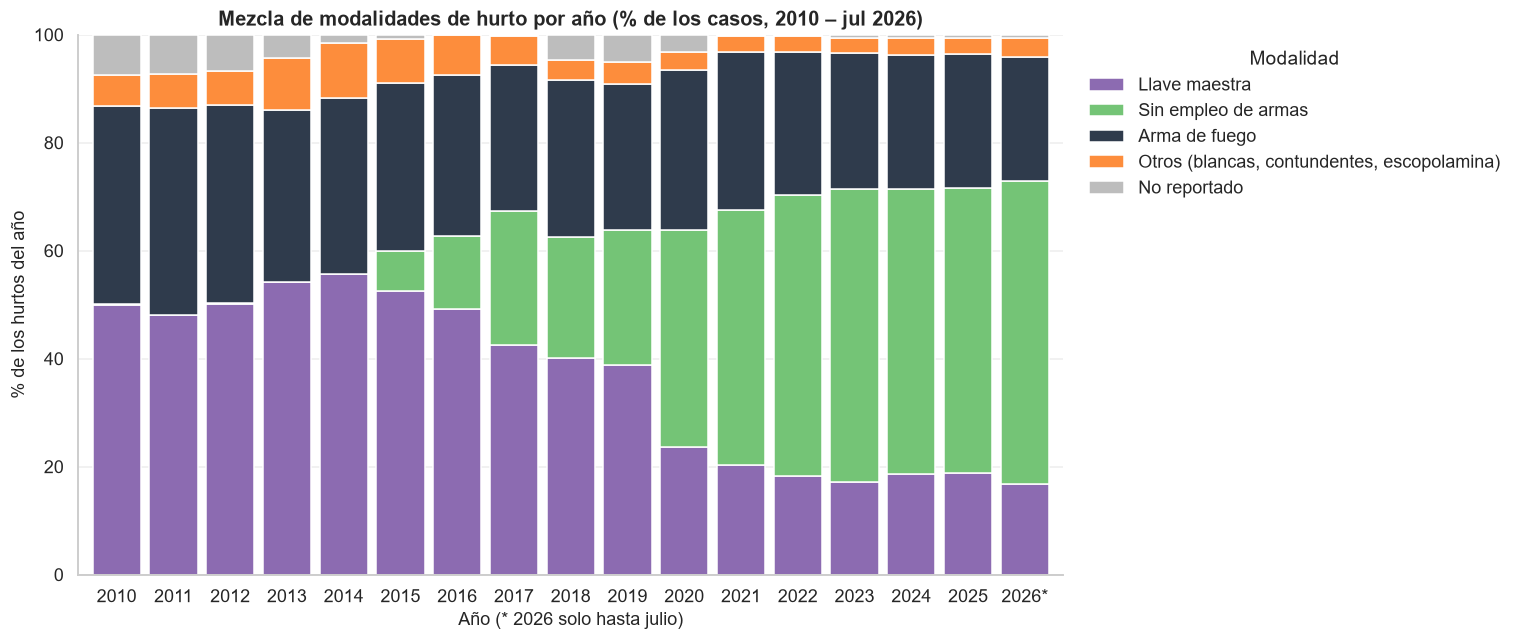

ARMAS  Llave maestra  Sin empleo de armas  Arma de fuego  Otros (blancas, contundentes, escopolamina)  No reportado
2010            50.0                  0.0           36.7                                          5.8           7.4
2015            52.6                  7.2           31.2                                          8.3           0.7
2019            38.9                 24.9           27.1                                          4.1           5.0
2020            23.7                 40.0           29.8                                          3.3           3.2
2025            18.8                 52.8           24.7                                          3.1           0.5


In [21]:
mezcla = (pd.crosstab(df["ANIO"], df["ARMAS"], normalize="index") * 100)[orden_a]
mezcla.index = [f"{a}*" if a == 2026 else str(a) for a in mezcla.index]

ax = mezcla.plot(kind="bar", stacked=True, figsize=(14, 6), color=["#8c6bb1", "#74c476", "#2F3B4C", "#fd8d3c", "#bdbdbd"], width=0.85)
ax.set_title("Mezcla de modalidades de hurto por año (% de los casos, 2010 – jul 2026)")
ax.set_xlabel("Año (* 2026 solo hasta julio)")
ax.set_ylabel("% de los hurtos del año")
ax.set_ylim(0, 100)
ax.legend(title="Modalidad", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(mezcla.loc[["2010", "2015", "2019", "2020", "2025"]].round(1).to_string())

**Insight:** la llave maestra baja de **50 % (2010) a 19 % (2025)** y "sin empleo de armas" pasa de casi 0 % a **53 %**, mientras el arma de fuego cae de 37 % a 25 %. Un cambio tan brusco (sobre todo desde 2015 y en 2020) sugiere un **cambio en cómo se clasifican los casos** y no solo en cómo delinquen. Antes de comparar modalidades entre años hay que verificar los criterios con la Policía Nacional.

### 7.5 Estacionalidad — ¿hay temporadas de más hurtos?
**Qué vamos a ver:** para que no domine la **tendencia** (los años recientes tienen más hurtos), cada celda del mapa mes × año es un **índice**: 100 = el mes promedio de ese año, ajustado por los días del mes. **Rojo = mes por encima de lo normal; azul = por debajo.** A la derecha, la desviación típica por mes y por día de la semana (mediana de 2010–2025).

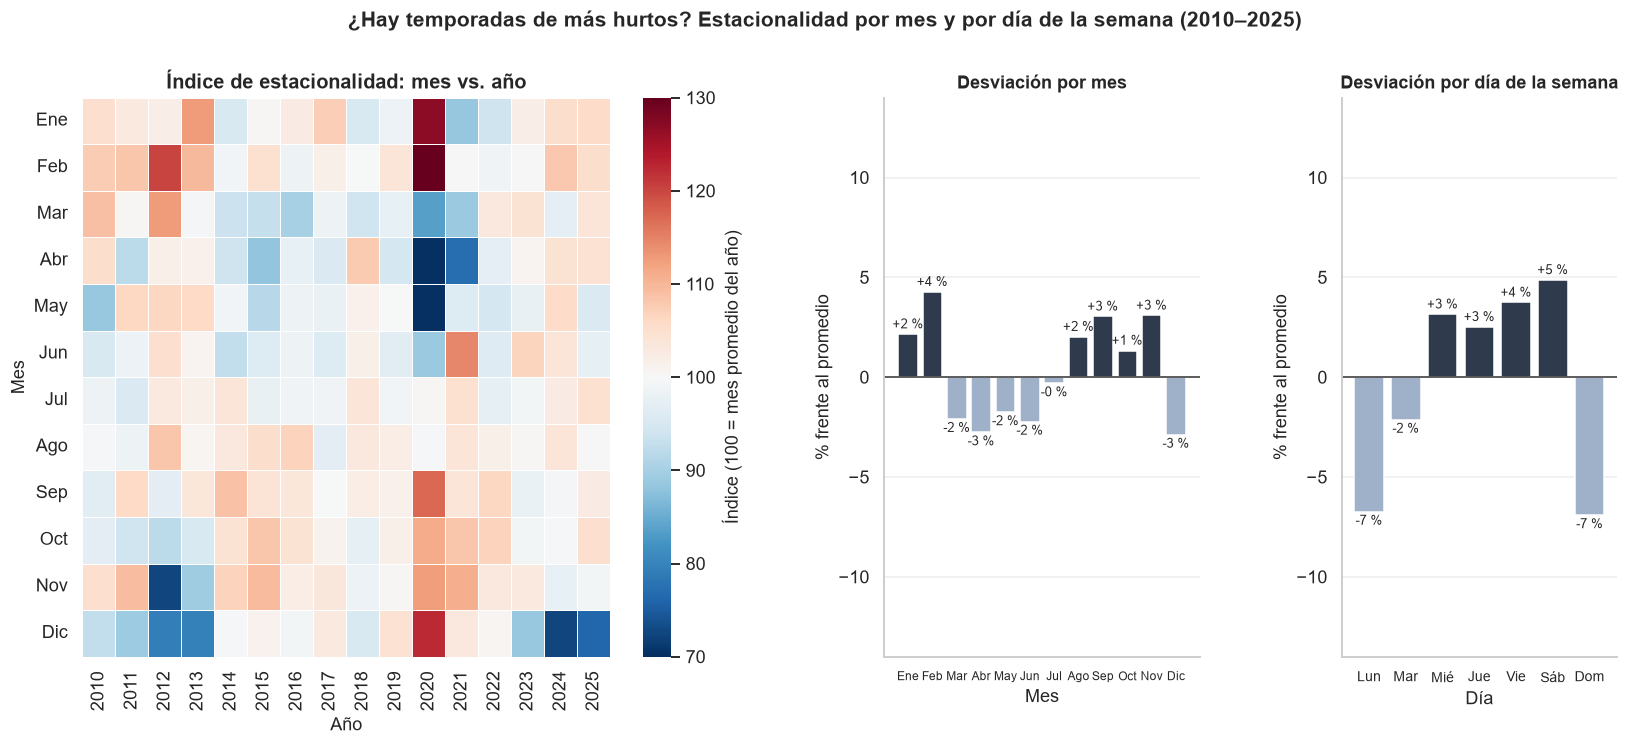

Índice de diciembre en 2012, 2013, 2024, 2025: [79.0, 80.0, 73.0, 76.0]
Índice de abril 2020: 35 | enero-febrero 2020: [127.0, 132.0]
Desviación por mes (%): [2.2, 4.3, -2.1, -2.8, -1.8, -2.2, -0.3, 2.0, 3.0, 1.3, 3.1, -2.9]
Desviación por día (%): [-6.7, -2.1, 3.1, 2.5, 3.7, 4.9, -6.9]
Rango del índice mes-año: 35 a 132


In [22]:
completo = df[df["ANIO"] <= 2025]

# Índice mes x año (100 = mes promedio del año, ajustado por días del mes)
mens = completo.groupby(["ANIO", "MES"]).size().rename("n").reset_index()
mens["dias"] = pd.to_datetime(dict(year=mens["ANIO"], month=mens["MES"], day=1)).dt.days_in_month
mens["por_dia"] = mens["n"] / mens["dias"]
idx = mens.pivot(index="MES", columns="ANIO", values="por_dia")
idx = idx / idx.mean() * 100
dev_mes = idx.median(axis=1) - 100

# Índice por día de la semana (se divide entre cuántas veces ocurre cada día en el año)
cal = pd.DataFrame({"FECHA": pd.date_range("2010-01-01", "2025-12-31")})
cal["ANIO"], cal["DIA_SEM"] = cal["FECHA"].dt.year, cal["FECHA"].dt.dayofweek
ocurrencias = cal.groupby(["ANIO", "DIA_SEM"]).size().rename("veces")
sem = completo.groupby(["ANIO", "DIA_SEM"]).size().rename("n").to_frame().join(ocurrencias)
sem = (sem["n"] / sem["veces"]).unstack()
sem = sem.div(sem.mean(axis=1), axis=0) * 100
dev_sem = sem.median() - 100

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
dias_n = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig = plt.figure(figsize=(18, 6.6))
gs = fig.add_gridspec(1, 3, width_ratios=[2.4, 1.15, 1], wspace=0.34)
ax = fig.add_subplot(gs[0])
sns.heatmap(idx, cmap="RdBu_r", center=100, vmin=70, vmax=130, linewidths=0.4, ax=ax,
            yticklabels=meses, cbar_kws={"label": "Índice (100 = mes promedio del año)"})
ax.set_title("Índice de estacionalidad: mes vs. año")
ax.set_xlabel("Año"); ax.set_ylabel("Mes")
ax.tick_params(axis="y", rotation=0)

for pos, serie, etiquetas_b, titulo, xl_b in [(1, dev_mes, meses, "Desviación por mes", "Mes"), (2, dev_sem, dias_n, "Desviación por día de la semana", "Día")]:
    a = fig.add_subplot(gs[pos])
    colores = [C_OSC if v >= 0 else C_CLARO for v in serie.values]
    barras = a.bar(range(len(serie)), serie.values, color=colores)
    a.bar_label(barras, labels=[f"{v:+.0f} %" for v in serie.values], fontsize=8.5, padding=2)
    a.axhline(0, color="#333", lw=1)
    a.set_xticks(range(len(serie))); a.set_xticklabels(etiquetas_b, rotation=0, fontsize=8 if pos == 1 else 9)
    a.set_ylim(-14, 14)
    a.set_title(titulo, fontsize=11.5)
    a.set_xlabel(xl_b); a.set_ylabel("% frente al promedio")
    a.grid(axis="x", visible=False)
fig.suptitle("¿Hay temporadas de más hurtos? Estacionalidad por mes y por día de la semana (2010–2025)", fontsize=14, fontweight="bold", y=1.0)
plt.show()
print("Índice de diciembre en 2012, 2013, 2024, 2025:", idx.loc[12, [2012, 2013, 2024, 2025]].round(0).tolist())
print("Índice de abril 2020:", round(idx.loc[4, 2020]), "| enero-febrero 2020:", idx.loc[[1, 2], 2020].round(0).tolist())
print("Desviación por mes (%):", dev_mes.round(1).tolist())
print("Desviación por día (%):", dev_sem.round(1).tolist())
print(f"Rango del índice mes-año: {idx.min().min():.0f} a {idx.max().max():.0f}")

**Insight:** **el hurto casi no tiene temporada**: ningún mes se aleja más de ±4 % del promedio, y el ritmo que sí se ve es el semanal (**lunes y domingo ≈ 7 % por debajo; sábado ≈ 5 % por encima**). Las manchas fuertes del mapa son eventos, no estaciones: enero–febrero de 2020 (+27 % y +32 %), la cuarentena (abril de 2020 en 35) y diciembres bajos en 2012–2013 y 2024–2025 (73 a 80), que podrían ser rezago de registro. Para planear operativos importa más el día de la semana que la época del año; y para el modelo mensual, el mes del año será una variable de poco peso frente a la historia reciente del municipio.

### 7.6 Burbujas — ¿cada región hurta de la misma manera?
**Qué vamos a ver:** un gráfico de burbujas (Clase 4) cruza **tres variables** a la vez. Cada burbuja es un departamento: a la derecha hay más motos entre sus hurtos, arriba más uso de arma de fuego y el **tamaño** es el total de hurtos.

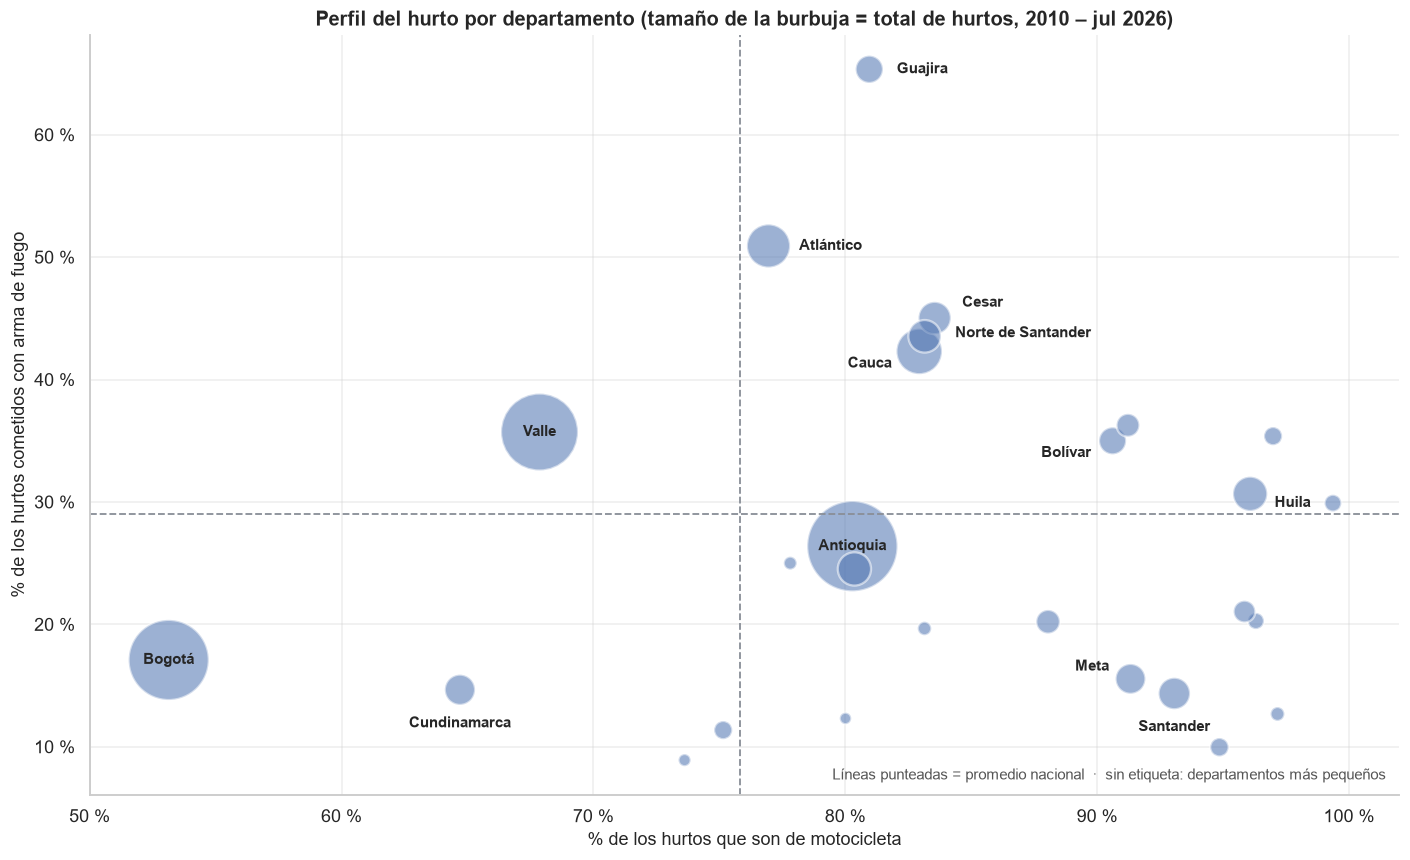

            nombre      n  pct_moto  pct_fuego
         Antioquia 144040      80.3       26.4
            Bogotá 113399      53.1       17.1
             Valle 104537      67.9       35.7
             Cauca  36692      82.9       42.3
         Atlántico  33000      77.0       50.9
             Huila  20806      96.1       30.7
            Nariño  19534      80.4       24.5
Norte de Santander  18719      83.2       43.5
             Cesar  18497      83.5       45.0
         Santander  17530      93.1       14.4
      Cundinamarca  16199      64.7       14.7
              Meta  15733      91.3       15.5
           Guajira  13194      81.0       65.3
           Bolívar  12985      90.6       35.0


In [23]:
dpt = (df.groupby("DEPARTAMENTO")
       .agg(n=("TIPO", "size"), pct_moto=("TIPO", lambda s: (s == "Motocicletas").mean() * 100),
            pct_fuego=("ARMAS", lambda s: (s == "Arma de fuego").mean() * 100))
       .reset_index())
dpt["nombre"] = bonito(dpt["DEPARTAMENTO"])
dpt = dpt[dpt["n"] >= 2000]          # departamentos con volumen suficiente para comparar porcentajes

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(dpt["pct_moto"], dpt["pct_fuego"], s=dpt["n"] / dpt["n"].max() * 3500, alpha=0.55, color=C_AUTO, edgecolor="white", lw=1.5)
ax.axhline(df["ARMAS"].eq("Arma de fuego").mean() * 100, color=C_GRIS, ls="--", lw=1.2)
ax.axvline(df["TIPO"].eq("Motocicletas").mean() * 100, color=C_GRIS, ls="--", lw=1.2)
# etiquetas: (desplazamiento en puntos, alineación) para que no se pisen
pos_etiq = {"Antioquia": ((0, 0), "center"), "Bogotá": ((0, 0), "center"), "Valle": ((0, 0), "center"),
            "Cauca": ((-18, -8), "right"), "Atlántico": ((20, 0), "left"), "Huila": ((16, -6), "left"),
            "Norte de Santander": ((20, 2), "left"), "Cesar": ((18, 10), "left"), "Santander": ((0, -22), "center"),
            "Cundinamarca": ((0, -22), "center"), "Meta": ((-14, 8), "right"), "Guajira": ((18, 0), "left"),
            "Bolívar": ((-14, -8), "right")}
for _, f in dpt.iterrows():
    if f["nombre"] in pos_etiq:
        (dx, dy), ha = pos_etiq[f["nombre"]]
        ax.annotate(f["nombre"], (f["pct_moto"], f["pct_fuego"]), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va="center", fontsize=10, fontweight="bold")
ax.text(0.99, 0.02, "Líneas punteadas = promedio nacional  ·  sin etiqueta: departamentos más pequeños", transform=ax.transAxes,
        ha="right", fontsize=9.5, color="#555")
ax.set_xlim(50, 102)
ax.set_title("Perfil del hurto por departamento (tamaño de la burbuja = total de hurtos, 2010 – jul 2026)")
ax.set_xlabel("% de los hurtos que son de motocicleta")
ax.set_ylabel("% de los hurtos cometidos con arma de fuego")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
plt.tight_layout()
plt.show()
print(dpt.sort_values("n", ascending=False).head(14)[["nombre", "n", "pct_moto", "pct_fuego"]].round(1).to_string(index=False))

**Insight:** **no hay un solo perfil nacional**: el arma de fuego pesa 65 % en Guajira, 51 % en Atlántico y 45 % en Cesar, pero solo 14 % en Santander y 15 % en Meta; y Bogotá es el lugar donde menos pesan las motos (53 %), frente a 93 % en Santander y 96 % en Huila. Antioquia, Bogotá y Valle son las burbujas más grandes, pero con perfiles muy distintos entre sí. Las políticas deben adaptarse a cada región.

## 8. Perfil de las víctimas
Lo resumimos en una tabla: es contexto útil, pero no es el centro de la pregunta de negocio.

In [24]:
genero = (df["GENERO"].value_counts(normalize=True) * 100).round(1)
etario = (df["GRUPO ETARIO"].value_counts(normalize=True, dropna=False) * 100).round(2)
mujer_anio = (df[(df["GENERO"] != "SIN DATO") & (df["ANIO"] <= 2025)]
              .groupby("ANIO")["GENERO"].apply(lambda s: (s == "FEMENINO").mean() * 100))
print("Género de la víctima (%):\n", genero.to_string())
print("\nGrupo etario (%):\n", etario.to_string())
print("\n% de víctimas mujeres por año:", mujer_anio.round(1).loc[[2010, 2015, 2020, 2025]].to_dict())

Género de la víctima (%):
 GENERO
MASCULINO    80.7
FEMENINO     19.2
SIN DATO      0.1

Grupo etario (%):
 GRUPO ETARIO
ADULTOS         99.32
ADOLESCENTES     0.55
MENORES          0.09
NaN              0.03

% de víctimas mujeres por año: {2010: 17.2, 2015: 18.0, 2020: 20.7, 2025: 21.5}


**Lectura rápida:** 8 de cada 10 víctimas son hombres (80,7 %) y el porcentaje de mujeres sube lentamente, de 17,2 % en 2010 a 21,5 % en 2025. `GRUPO ETARIO` es casi constante (99,3 % adultos): no ayuda a distinguir municipios ni meses, así que **no es útil como variable predictora** y en la Fase B puede descartarse.

## 9. Hallazgos, limitaciones e implicaciones

**Tres hallazgos principales**
1. **El hurto de vehículos está extremadamente concentrado (Ley de Pareto).** Solo 52 de 1.052 municipios (4,9 %) reúnen el 80 % de los casos, y Bogotá, Medellín y Cali suman el 44 %. En automotores la concentración es aún mayor (18 municipios hacen el 80 %), por lo que los recursos rinden más si se focalizan.
2. **Las motos son el centro del problema y su tendencia ya cambió.** Son el 76 % de los hurtos y crecieron ≈ ×2,0 entre 2011 y 2023 (el ×3,1 que sale desde 2010 está inflado por un registro incompleto de ese año). Desde 2023 bajan (−17 % en 2025), algo que conviene confirmar con la fuente.
3. **El hurto de motos de un municipio se puede anticipar con su propia historia.** Cada ciudad se mueve en su propia franja y el promedio de los 3 meses previos se correlaciona 0,63 (Spearman) con el mes siguiente. Una predicción ingenua ya logra un error medio de 0,84 motos por municipio-mes: esa es la línea base que deben superar los modelos.

**Otros hallazgos**
- Tres modalidades (llave maestra, sin empleo de armas y arma de fuego) explican el 93 % de los casos; en carros domina la llave maestra (44 %) y en motos el hurto sin armas (32 %).
- El hurto casi no tiene temporada mensual (±4 %); el ritmo que sí existe es semanal (sábado alto, domingo y lunes ≈ 7 % por debajo).
- Cada región hurta distinto: el arma de fuego pesa 65 % en La Guajira y solo 14 % en Santander.

**Limitaciones de los datos**
- `CANTIDAD` es siempre 1, `CODIGO DANE` cambia según el centro poblado y 58 nombres de municipio se repiten entre departamentos; por eso la llave del municipio es departamento + municipio.
- 2026 está incompleto (hasta el 31 de julio) y 2010 parece subregistrado (el conteo salta +59 % en enero de 2011).
- Una de cada tres filas está repetida; se conservan porque no hay identificador de caso (borrarlas subestimaría el problema).
- En la variable objetivo, un 0 puede significar "no hubo hurtos" o "no se registró": hay huecos de registro (por ejemplo, noviembre–diciembre de 2012 en Medellín y Bello).
- Los criterios de `ARMAS MEDIOS` cambiaron con el tiempo (la llave maestra pasa de 50 % a 19 %), así que la modalidad no es comparable entre años.
- Son hurtos **registrados** (denunciados), no necesariamente todos los que ocurrieron.

**Implicaciones para las fases B y C**
- **Fase B (limpieza):** transformar los conteos con log(1 + x) (la asimetría baja de 15,9 a 1,35); conservar los atípicos porque son ciudades reales; imputar los pocos vacíos de `GENERO` (0,1 %) y descartar `GRUPO ETARIO`; codificar modalidad y departamento con One-Hot; trabajar la serie desde 2011.
- **Fase C (modelos):** usar como variables la historia del municipio (mes anterior, promedio de 3 meses, mismo mes del año anterior, autos del mes anterior), el mes y el departamento; separar entrenamiento y prueba **en el tiempo** (entrenar con meses antiguos y evaluar con los más recientes) para no usar información del futuro; comparar siempre contra la línea base ingenua (error medio de 0,84).